### imports

### config 

In [1]:
from contextlib import contextmanager, redirect_stderr, redirect_stdout
from functools import wraps
from pathlib import Path
import sys

LOCAL_OUTPUT_DIR = Path("/Users/romanpempus/Desktop/AI/hw_2/outputs")
LOCAL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_LOG_DIR = LOCAL_OUTPUT_DIR / "logs"
CHECKPOINT_OUTPUT_DIR = LOCAL_OUTPUT_DIR / "checkpoints"
EDA_OUTPUT_DIR = LOCAL_OUTPUT_DIR / "eda"
FAILURE_OUTPUT_DIR = LOCAL_OUTPUT_DIR / "failures"


class _TeeStream:
    def __init__(self, *streams):
        self.streams = streams

    def write(self, text):
        for stream in self.streams:
            stream.write(text)
            stream.flush()
        return len(text)

    def flush(self):
        for stream in self.streams:
            stream.flush()

    def isatty(self):
        return any(getattr(stream, "isatty", lambda: False)() for stream in self.streams)


@contextmanager
def tee_output(log_path: str | Path):
    log_path = Path(log_path)
    log_path.parent.mkdir(parents=True, exist_ok=True)
    with log_path.open("a", encoding="utf-8", buffering=1) as log_file:
        stdout_tee = _TeeStream(sys.stdout, log_file)
        stderr_tee = _TeeStream(sys.stderr, log_file)
        with redirect_stdout(stdout_tee), redirect_stderr(stderr_tee):
            yield


def append_output_log(log_path: str | Path, text: str) -> None:
    log_path = Path(log_path)
    log_path.parent.mkdir(parents=True, exist_ok=True)
    with log_path.open("a", encoding="utf-8") as log_file:
        log_file.write(text.rstrip() + "\n")


def tee_training_run(log_filename: str):
    def decorate(function):
        @wraps(function)
        def wrapped(*args, **kwargs):
            with tee_output(OUTPUT_LOG_DIR / log_filename):
                return function(*args, **kwargs)
        return wrapped
    return decorate
SHARED_CONFIG = {
    "manifest": "/content/outputs/eda/sequence_split.csv",
    "frame_skip": 35,          # Drops train set to ~690 frames (~22 steps/epoch at batch 32)
    "image_size": 448,         # Keeps spatial resolution intact for small drone targets
    "batch_size": 32,          # Saturates GPU memory without OOM at 448px
    "epochs": 3,               # Total run time: ~2.5 mins per architecture
    "seed": 42,
    "mask_ignore_pixels": True,
    "max_detections": 500,
    "save_dir": "./outputs/checkpoints",
}


def download_checkpoint(checkpoint_path: str | Path) -> None:
    if Path("/content").is_dir():
        from google.colab import files

        files.download(str(checkpoint_path))

### get data

In [2]:
import json, os, subprocess
from pathlib import Path
from getpass import getpass

raw = getpass("Paste your Kaggle token or kaggle.json content: ").strip()
if raw.startswith("export KAGGLE_API_TOKEN="):
    raw = raw.split("=", 1)[1].strip().strip('"').strip("'")

kaggle_dir = Path.home() / ".kaggle"
kaggle_dir.mkdir(exist_ok=True)

if raw.startswith("{"):
    # Legacy kaggle.json format
    creds = json.loads(raw)
    os.environ["KAGGLE_USERNAME"] = creds["username"]
    os.environ["KAGGLE_KEY"] = creds["key"]
    p = kaggle_dir / "kaggle.json"
    p.write_text(json.dumps(creds))
    p.chmod(0o600)
    print("Configured legacy kaggle.json")
elif raw.startswith("KGAT_"):
    # New KGAT access token format
    os.environ["KAGGLE_API_TOKEN"] = raw
    p = kaggle_dir / "access_token"
    p.write_text(raw)
    p.chmod(0o600)
    print("Configured KGAT access_token")
else:
    raise ValueError(f"Unrecognized format (starts with '{raw[:6]}...'). Paste either a KGAT_... token or the full {{'username': ...}} JSON.")

!kaggle competitions files -c multiple-object-video-detection-hw-2-ucu-ai-2026

Configured KGAT access_token
Next Page Token = CfDJ8CXkJvnxKG5Ktgac76JjV5FW2UY9N1S4_y6jRqRYaszrLWL6q6UX4z5DhcP9rdPq1lKRfqKuXn7RLn39PdffBlGunRATGYx-fhz8A9mr_KtkcWy-jkGKomdLpBlfVoW7JLxABvmDvrYomxkvPOxB6ZoQXZ35wvC_VLBoTg
name                                    size  creationDate                
--------------------------------  ----------  --------------------------  
test/images/clip_001/0000001.jpg      244538  2026-10-20 08:31:52.810000  
test/images/clip_001/0000002.jpg      242544  2026-10-20 08:31:52.918000  
test/images/clip_001/0000003.jpg      237298  2026-10-20 08:31:52.834000  
test/images/clip_001/0000004.jpg      210540  2026-10-20 08:31:52.829000  
test/images/clip_001/0000005.jpg      227096  2026-10-20 08:31:52.845000  
test/images/clip_001/0000006.jpg      241796  2026-10-20 08:31:52.850000  
test/images/clip_001/0000007.jpg      241542  2026-10-20 08:31:52.834000  
test/images/clip_001/0000008.jpg      242601  2026-10-20 08:31:52.858000  
test/images/clip_001/0000009.jpg

In [ ]:
!kaggle competitions download -c multiple-object-video-detection-hw-2-ucu-ai-2026 -p /content && \
 unzip -oq /content/multiple-object-video-detection-hw-2-ucu-ai-2026.zip -d /content/data && \
 rm /content/multiple-object-video-detection-hw-2-ucu-ai-2026.zip && \
 ls -lh /content/data

100% 9.88G/9.88G [01:59<00:00, 88.5MB/s]



### eda

Successfully parsed 27047 frames from /content/data
⚠️ Validation warnings: 13151 total (showing first 5):
  • /content/data/train/labels/uav0000013_00000_v/0000214.txt:14: box extends beyond the bottom or right image edge
  • /content/data/train/labels/uav0000013_01392_v/0000118.txt:2: box extends beyond the top or left image edge
  • /content/data/train/labels/uav0000020_00406_v/0000367.txt:2: box extends beyond the top or left image edge
  • /content/data/train/labels/uav0000020_00406_v/0000371.txt:1: box extends beyond the top or left image edge
  • /content/data/train/ignore/uav0000071_03240_v/0000001.txt:2: box extends beyond the top or left image edge
  ... [13146 additional minor warnings hidden for clean output]



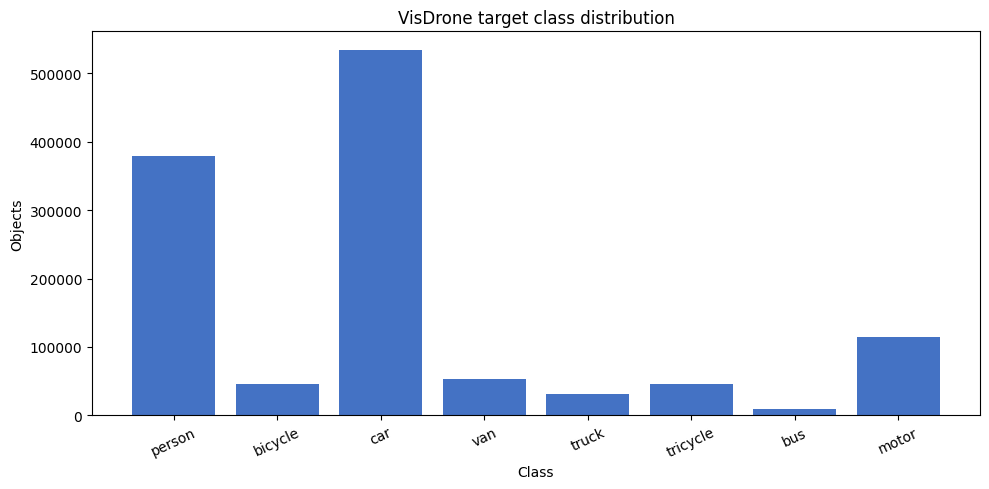

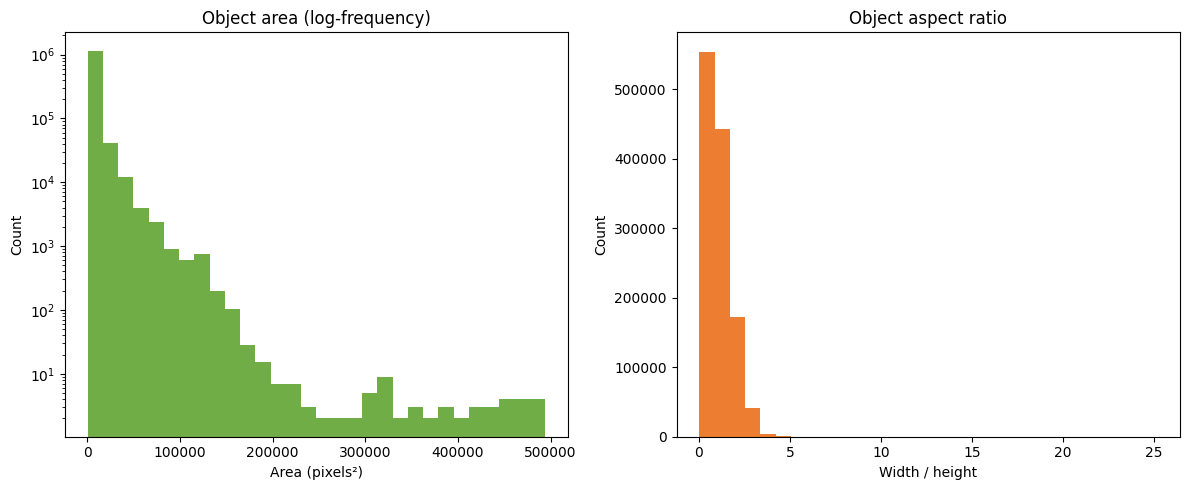

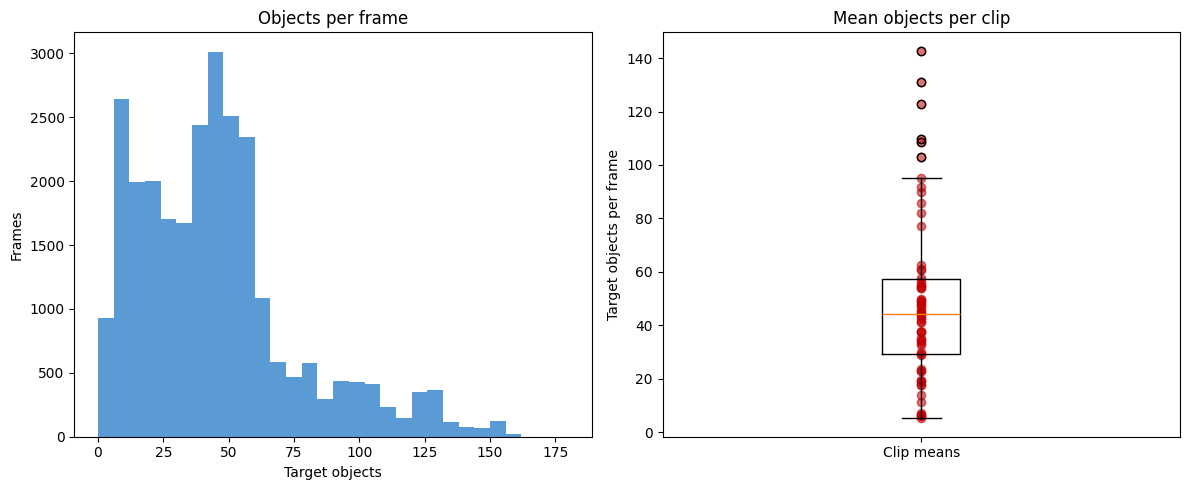

Frames: 27047 across 63 clips
Target objects: 1215403

Class distribution:
  0: person     378569 ( 31.1%)
  1: bicycle     46231 (  3.8%)
  2: car        534171 ( 44.0%)
  3: van         53645 (  4.4%)
  4: truck       31689 (  2.6%)
  5: tricycle    46671 (  3.8%)
  6: bus          9830 (  0.8%)
  7: motor      114597 (  9.4%)
Most common classes: car (534171), person (378569), motor (114597)
Object sizes by COCO area bins: small=296450 (24.4%), medium=778989 (64.1%), large=139964 (11.5%)
Object area (pixels²): min=60.00, max=494216.20, mean=4757.94, median=2145.97
Object aspect ratio: min=0.03, max=25.16, mean=1.10, median=0.93

Objects per frame: min=0.00, max=180.00, mean=44.94, median=42.00
Total objects per sequence: min=706.00, max=64214.00, mean=19292.11, median=16363.00

Objects per clip (per-frame min/max/mean/median):
  uav0000013_00000_v: min=23.00, max=37.00, mean=28.94, median=30.00
  uav0000013_01073_v: min=14.00, max=23.00, mean=17.74, median=18.00
  uav0000013_01392_v

In [24]:
"""Exploratory data analysis and validation for the VisDrone YOLO dataset.

Colab & Local Compatible Version:
- Displays plots inline in Jupyter / Colab notebooks.
- Auto-detects Colab / Kaggle dataset paths if defaults aren't specified.
- Safely handles main execution in notebook environments.
"""

from __future__ import annotations

import argparse
import csv
import io
import math
import os
import random
import re
import statistics
import sys
from contextlib import redirect_stdout
from collections import Counter, defaultdict
from dataclasses import dataclass
from pathlib import Path
from typing import Iterable

import matplotlib.pyplot as plt
from PIL import Image, UnidentifiedImageError

# Enable inline display if running inside Jupyter / Google Colab
try:
    from IPython.display import display
    IN_NOTEBOOK = True
except ImportError:
    IN_NOTEBOOK = False

CLASS_NAMES = (
    "person",
    "bicycle",
    "car",
    "van",
    "truck",
    "tricycle",
    "bus",
    "motor",
)
IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
TRAILING_NUMBER = re.compile(r"-\d+$")
COCO_SMALL_AREA = 32**2
COCO_MEDIUM_AREA = 96**2


@dataclass(frozen=True)
class Box:
    """A normalized YOLO box; ``class_id`` is absent for ignored regions."""
    cx: float
    cy: float
    width: float
    height: float
    class_id: int | None = None


@dataclass
class FrameMetadata:
    """Parsed annotation and image metadata for one frame."""
    clip_id: str
    frame_id: str
    image_path: Path
    source_split: str
    image_size: tuple[int, int]
    object_list: list[Box]
    ignore_list: list[Box]


def _normalized_stem(stem: str) -> str:
    """Remove a trailing numeric export suffix from a frame or label stem."""
    return TRAILING_NUMBER.sub("", stem)


def _parse_annotation(
    path: Path,
    expected_values: int,
    issues: list[str],
) -> list[Box]:
    """Read one annotation file, recording malformed rows as validation issues."""
    boxes: list[Box] = []
    try:
        lines = path.read_text(encoding="utf-8").splitlines()
    except OSError as error:
        issues.append(f"{path}: could not read annotation ({error})")
        return boxes

    for line_number, line in enumerate(lines, start=1):
        fields = line.split()
        if not fields:
            continue
        if len(fields) != expected_values:
            issues.append(
                f"{path}:{line_number}: expected {expected_values} values, "
                f"found {len(fields)}"
            )
            continue
        try:
            values = [float(field) for field in fields]
        except ValueError:
            issues.append(f"{path}:{line_number}: contains a non-numeric value")
            continue
        if not all(math.isfinite(value) for value in values):
            issues.append(f"{path}:{line_number}: values must be finite")
            continue

        if expected_values == 5:
            raw_class_id, cx, cy, width, height = values
            class_id = int(raw_class_id)
            if raw_class_id != class_id or not 0 <= class_id < len(CLASS_NAMES):
                issues.append(
                    f"{path}:{line_number}: class id must be an integer from "
                    f"0 to {len(CLASS_NAMES) - 1}"
                )
                continue
        else:
            cx, cy, width, height = values
            class_id = None

        if width <= 0 or height <= 0:
            issues.append(f"{path}:{line_number}: box width and height must be positive")
            continue
        if not (
            0 <= cx <= 1
            and 0 <= cy <= 1
            and 0 < width <= 1
            and 0 < height <= 1
        ):
            issues.append(
                f"{path}:{line_number}: normalized centers and dimensions must be in [0, 1]"
            )
            continue
        if cx - width / 2 < 0 or cy - height / 2 < 0:
            issues.append(f"{path}:{line_number}: box extends beyond the top or left image edge")
            continue
        if cx + width / 2 > 1 or cy + height / 2 > 1:
            issues.append(
                f"{path}:{line_number}: box extends beyond the bottom or right image edge"
            )
            continue
        boxes.append(Box(cx, cy, width, height, class_id))
    return boxes


def _flat_annotation_kind(path: Path, issues: list[str]) -> str | None:
    """Infer a flat annotation file's role from its first non-empty row."""
    try:
        lines = path.read_text(encoding="utf-8").splitlines()
    except OSError as error:
        issues.append(f"{path}: could not read annotation ({error})")
        return None
    for line_number, line in enumerate(lines, start=1):
        fields = line.split()
        if not fields:
            continue
        if len(fields) == 5:
            return "objects"
        if len(fields) == 4:
            return "ignore"
        issues.append(
            f"{path}:{line_number}: cannot classify flat annotation with "
            f"{len(fields)} values"
        )
        return None
    issues.append(f"{path}: empty flat annotation cannot be classified")
    return None


def _image_dimensions(path: Path, issues: list[str]) -> tuple[int, int] | None:
    """Read image dimensions and verify that the image can be opened."""
    try:
        with Image.open(path) as image:
            width, height = image.size
            image.verify()
    except (OSError, UnidentifiedImageError) as error:
        issues.append(f"{path}: unreadable image ({error})")
        return None
    if width <= 0 or height <= 0:
        issues.append(f"{path}: invalid image dimensions {width}x{height}")
        return None
    return width, height


def _clip_id(image_path: Path, image_root: Path, split_name: str) -> str:
    """Use the first image subdirectory as a sequence ID."""
    relative = image_path.relative_to(image_root)
    if len(relative.parts) > 1:
        return relative.parts[0]
    return f"flat:{split_name}"


def _flat_annotation_index(
    split_root: Path,
    issues: list[str],
) -> dict[str, list[tuple[str, Path]]]:
    """Index annotations in a flat dataset by their normalized frame stem."""
    index: dict[str, list[tuple[str, Path]]] = defaultdict(list)
    for path in sorted(split_root.rglob("*.txt")):
        kind = _flat_annotation_kind(path, issues)
        if kind is not None:
            index[_normalized_stem(path.stem)].append((kind, path))
    return index


def _read_flat_annotations(
    image_path: Path,
    index: dict[str, list[tuple[str, Path]]],
    issues: list[str],
) -> tuple[list[Box], list[Box]]:
    """Load object and ignore files associated with a flat-layout image."""
    candidates = index.get(_normalized_stem(image_path.stem), [])
    selected: list[tuple[str, Path]] = []
    for kind in ("objects", "ignore"):
        matching_kind = [entry for entry in candidates if entry[0] == kind]
        exact = [entry for entry in matching_kind if entry[1].stem == image_path.stem]
        selected.extend(exact or matching_kind)
    objects: list[Box] = []
    ignores: list[Box] = []
    for kind, path in selected:
        target = objects if kind == "objects" else ignores
        expected_values = 5 if kind == "objects" else 4
        target.extend(_parse_annotation(path, expected_values, issues))
    return objects, ignores


def parse_split(split_root: Path, split_name: str) -> tuple[list[FrameMetadata], list[str]]:
    """Parse one train/validation directory and return frame metadata and issues."""
    issues: list[str] = []
    image_root = split_root / "images"
    if not image_root.is_dir():
        image_root = split_root
    image_paths = sorted(
        path
        for path in image_root.rglob("*")
        if path.is_file() and path.suffix.lower() in IMAGE_SUFFIXES
    )
    if not image_paths:
        issues.append(f"{split_root}: no supported image files found")
        return [], issues

    labels_root = split_root / "labels"
    ignore_root = split_root / "ignore"
    has_separate_annotations = labels_root.is_dir() or ignore_root.is_dir()
    flat_index = (
        {}
        if has_separate_annotations
        else _flat_annotation_index(split_root, issues)
    )
    frames: list[FrameMetadata] = []

    for image_path in image_paths:
        dimensions = _image_dimensions(image_path, issues)
        if dimensions is None:
            continue
        if has_separate_annotations:
            relative = image_path.relative_to(image_root)
            object_path = labels_root / relative.parent / f"{image_path.stem}.txt"
            ignore_path = ignore_root / relative.parent / f"{image_path.stem}.txt"
            objects = (
                _parse_annotation(object_path, 5, issues)
                if object_path.is_file()
                else []
            )
            ignores = (
                _parse_annotation(ignore_path, 4, issues)
                if ignore_path.is_file()
                else []
            )
            if labels_root.is_dir() and not object_path.is_file():
                issues.append(f"{image_path}: missing object annotation {object_path}")
            if ignore_root.is_dir() and not ignore_path.is_file():
                issues.append(f"{image_path}: missing ignore annotation {ignore_path}")
        else:
            objects, ignores = _read_flat_annotations(image_path, flat_index, issues)
            if not objects and not ignores:
                issues.append(f"{image_path}: no matching flat annotation file")

        frames.append(
            FrameMetadata(
                clip_id=_clip_id(image_path, image_root, split_name),
                frame_id=image_path.stem,
                image_path=image_path,
                source_split=split_name,
                image_size=dimensions,
                object_list=objects,
                ignore_list=ignores,
            )
        )
    return frames, issues


def split_by_clip(
    frames: list[FrameMetadata],
    validation_fraction: float,
    seed: int,
) -> dict[str, str]:
    """Assign each clip wholly to train or validation without frame leakage."""
    if not 0 < validation_fraction < 1:
        raise ValueError("validation_fraction must be strictly between 0 and 1")
    clip_ids = sorted({frame.clip_id for frame in frames})
    if len(clip_ids) < 2:
        raise ValueError("at least two distinct clips are required for a grouped split")
    shuffled = clip_ids.copy()
    random.Random(seed).shuffle(shuffled)
    validation_count = min(
        len(clip_ids) - 1,
        max(1, round(len(clip_ids) * validation_fraction)),
    )
    validation_clips = set(shuffled[:validation_count])
    assignments = {
        clip_id: ("val" if clip_id in validation_clips else "train")
        for clip_id in clip_ids
    }

    train_clips = {clip for clip, split in assignments.items() if split == "train"}
    val_clips = {clip for clip, split in assignments.items() if split == "val"}
    if train_clips & val_clips:
        raise RuntimeError("grouped split unexpectedly assigned a clip to both splits")
    return assignments


def _box_pixel_metrics(box: Box, image_size: tuple[int, int]) -> tuple[float, float, float]:
    """Return absolute width, height, and area for a normalized box."""
    image_width, image_height = image_size
    width = box.width * image_width
    height = box.height * image_height
    return width, height, width * height


def _describe(values: list[float]) -> str:
    """Format min/max/mean/median statistics for a non-empty numeric list."""
    return (
        f"min={min(values):.2f}, max={max(values):.2f}, "
        f"mean={statistics.mean(values):.2f}, median={statistics.median(values):.2f}"
    )


def _render_plot(figure: plt.Figure, output_path: Path) -> None:
    """Helper to save plot to disk and render inline if running in Colab/Jupyter."""
    figure.tight_layout()
    output_path.parent.mkdir(parents=True, exist_ok=True)
    figure.savefig(output_path, dpi=160)
    local_plot_path = Path(LOCAL_OUTPUT_DIR) / f"eda_{output_path.stem}.png"
    local_plot_path.parent.mkdir(parents=True, exist_ok=True)
    plt.figure(figure.number)
    plt.savefig(local_plot_path, bbox_inches="tight", dpi=300)
    if IN_NOTEBOOK:
        plt.show()
    plt.close(figure)


def _save_class_distribution(
    counts: Counter[int],
    output_dir: Path,
) -> None:
    """Save and display object counts for all target classes."""
    frequencies = [counts[class_id] for class_id in range(len(CLASS_NAMES))]
    figure, axis = plt.subplots(figsize=(10, 5))
    axis.bar(CLASS_NAMES, frequencies, color="#4472C4")
    axis.set(title="VisDrone target class distribution", xlabel="Class", ylabel="Objects")
    axis.tick_params(axis="x", rotation=25)
    _render_plot(figure, output_dir / "class_distribution.png")


def _save_object_size_distribution(
    areas: list[float],
    aspect_ratios: list[float],
    output_dir: Path,
) -> None:
    """Save and display histograms for object pixel area and width-to-height ratio."""
    figure, axes = plt.subplots(1, 2, figsize=(12, 5))
    if areas:
        axes[0].hist(areas, bins=30, color="#70AD47", log=True)
        axes[1].hist(aspect_ratios, bins=30, color="#ED7D31")
    else:
        axes[0].text(0.5, 0.5, "No target objects", ha="center", va="center")
        axes[1].text(0.5, 0.5, "No target objects", ha="center", va="center")
    axes[0].set(title="Object area (log-frequency)", xlabel="Area (pixels²)", ylabel="Count")
    axes[1].set(title="Object aspect ratio", xlabel="Width / height", ylabel="Count")
    _render_plot(figure, output_dir / "object_size_distribution.png")


def _save_scene_density(
    frames: list[FrameMetadata],
    output_dir: Path,
) -> None:
    """Save and display frame-level density and clip-level mean-density distributions."""
    by_clip: dict[str, list[int]] = defaultdict(list)
    for frame in frames:
        by_clip[frame.clip_id].append(len(frame.object_list))
    frame_counts = [len(frame.object_list) for frame in frames]
    clip_means = [statistics.mean(counts) for counts in by_clip.values()]

    figure, axes = plt.subplots(1, 2, figsize=(12, 5))
    if frame_counts:
        axes[0].hist(frame_counts, bins=min(30, max(1, len(set(frame_counts)))), color="#5B9BD5")
    else:
        axes[0].text(0.5, 0.5, "No frames", ha="center", va="center")
    if clip_means:
        axes[1].boxplot(clip_means)
        axes[1].scatter([1] * len(clip_means), clip_means, alpha=0.55, color="#C00000")
        axes[1].set_xticks([1], ["Clip means"])
    else:
        axes[1].text(0.5, 0.5, "No sequences", ha="center", va="center")
    axes[0].set(title="Objects per frame", xlabel="Target objects", ylabel="Frames")
    axes[1].set(
        title="Mean objects per clip",
        ylabel="Target objects per frame",
        xticks=[] if not clip_means else [1],
    )
    _render_plot(figure, output_dir / "scene_density.png")


def _write_split_manifest(
    frames: list[FrameMetadata],
    assignments: dict[str, str],
    output_path: Path,
) -> None:
    """Write the sequence-level split assignment without moving source files."""
    with output_path.open("w", newline="", encoding="utf-8") as manifest:
        writer = csv.writer(manifest)
        writer.writerow(("clip_id", "assigned_split", "source_split", "frame_id", "image_path"))
        for frame in frames:
            writer.writerow(
                (
                    frame.clip_id,
                    assignments[frame.clip_id],
                    frame.source_split,
                    frame.frame_id,
                    frame.image_path.as_posix(),
                )
            )


def _analyze(frames: list[FrameMetadata], output_dir: Path) -> None:
    """Calculate dataset metrics, print insights, and create the requested figures."""
    output_dir.mkdir(parents=True, exist_ok=True)
    class_counts: Counter[int] = Counter()
    object_areas: list[float] = []
    aspect_ratios: list[float] = []
    small_count = medium_count = large_count = 0
    frame_density: list[int] = []
    ignored_frame_coverages: list[float] = []
    all_frame_coverages: list[float] = []
    density_by_clip: dict[str, list[int]] = defaultdict(list)

    for frame in frames:
        width, height = frame.image_size
        frame_density.append(len(frame.object_list))
        density_by_clip[frame.clip_id].append(len(frame.object_list))
        for box in frame.object_list:
            assert box.class_id is not None
            class_counts[box.class_id] += 1
            pixel_width, pixel_height, area = _box_pixel_metrics(box, frame.image_size)
            object_areas.append(area)
            aspect_ratios.append(pixel_width / pixel_height)
            if area < COCO_SMALL_AREA:
                small_count += 1
            elif area <= COCO_MEDIUM_AREA:
                medium_count += 1
            else:
                large_count += 1

        ignored_area = sum(
            _box_pixel_metrics(box, frame.image_size)[2] for box in frame.ignore_list
        )
        coverage = ignored_area / (width * height)
        all_frame_coverages.append(coverage)
        if frame.ignore_list:
            ignored_frame_coverages.append(coverage)

    total_objects = sum(class_counts.values())
    print(f"Frames: {len(frames)} across {len(density_by_clip)} clips")
    print(f"Target objects: {total_objects}")
    print("\nClass distribution:")
    for class_id, class_name in enumerate(CLASS_NAMES):
        count = class_counts[class_id]
        percentage = (100 * count / total_objects) if total_objects else 0.0
        print(f"  {class_id}: {class_name:<10} {count:>6} ({percentage:5.1f}%)")
    if total_objects:
        most_common = class_counts.most_common(3)
        print(
            "Most common classes: "
            + ", ".join(f"{CLASS_NAMES[class_id]} ({count})" for class_id, count in most_common)
        )
        print(
            "Object sizes by COCO area bins: "
            f"small={small_count} ({100 * small_count / total_objects:.1f}%), "
            f"medium={medium_count} ({100 * medium_count / total_objects:.1f}%), "
            f"large={large_count} ({100 * large_count / total_objects:.1f}%)"
        )
        print(f"Object area (pixels²): {_describe(object_areas)}")
        print(f"Object aspect ratio: {_describe(aspect_ratios)}")

    print(f"\nObjects per frame: {_describe([float(value) for value in frame_density])}")
    sequence_totals = [sum(counts) for counts in density_by_clip.values()]
    print(
        "Total objects per sequence: "
        f"{_describe([float(value) for value in sequence_totals])}"
    )
    print("\nObjects per clip (per-frame min/max/mean/median):")
    for clip_id, counts in sorted(density_by_clip.items()):
        print(f"  {clip_id}: {_describe([float(value) for value in counts])}")

    ignored_frame_count = len(ignored_frame_coverages)
    ignored_proportion = 100 * ignored_frame_count / len(frames) if frames else 0.0
    print(
        f"\nFrames with ignored regions: {ignored_frame_count}/{len(frames)} "
        f"({ignored_proportion:.1f}%)"
    )
    if frames:
        conditional_coverage = (
            f"{100 * statistics.mean(ignored_frame_coverages):.2f}%"
            if ignored_frame_coverages
            else "n/a (no ignored regions)"
        )
        print(
            "Mean summed ignored-area coverage: "
            f"{conditional_coverage} on frames with regions; "
            f"{100 * statistics.mean(all_frame_coverages):.2f}% across all frames"
        )
    else:
        print("Mean summed ignored-area coverage: n/a (no frames)")

    _save_class_distribution(class_counts, output_dir)
    _save_object_size_distribution(object_areas, aspect_ratios, output_dir)
    _save_scene_density(frames, output_dir)
    print(f"\nFigures saved to {output_dir}")


def analyze(frames: list[FrameMetadata], output_dir: Path) -> None:
    report_buffer = io.StringIO()
    with redirect_stdout(report_buffer):
        _analyze(frames, output_dir)
    report = report_buffer.getvalue()
    summary_path = Path(LOCAL_OUTPUT_DIR) / "eda_summary.txt"
    summary_path.parent.mkdir(parents=True, exist_ok=True)
    summary_path.write_text(report, encoding="utf-8")
    print(report, end="")


def _detect_default_data_root() -> Path:
    """Auto-detect default dataset location based on local/Colab/Kaggle environment."""
    colab_data = Path("/content/data")
    kaggle_data = Path("/kaggle/input/multiple-object-video-detection-hw-2-ucu-ai-2026")

    try:
        local_data = Path(__file__).resolve().parent / "toy_data"
    except NameError:
        local_data = Path.cwd() / "toy_data"

    if colab_data.exists():
        return colab_data
    if kaggle_data.exists():
        return kaggle_data
    return local_data


def _build_parser() -> argparse.ArgumentParser:
    """Create the command-line argument parser."""
    project_dir = Path.cwd()
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument(
        "--data-root",
        type=Path,
        default=_detect_default_data_root(),
        help="directory containing train/ and val/",
    )
    parser.add_argument(
        "--output-dir",
        type=Path,
        default=Path(LOCAL_OUTPUT_DIR) / "eda",
        help="directory for plots and sequence split manifest",
    )
    parser.add_argument(
        "--validation-fraction",
        type=float,
        default=0.2,
        help="fraction of distinct clips assigned to validation split",
    )
    parser.add_argument("--seed", type=int, default=42, help="random seed for clip splitting")
    return parser

@tee_training_run("eda.txt")
def main(argv: Iterable[str] | None = None) -> int:
    """Run parsing, validation, grouped splitting, and EDA with clean output."""
    args = _build_parser().parse_args(argv)
    split_roots = (("train", args.data_root / "train"), ("val", args.data_root / "val"))
    missing_roots = [str(path) for _, path in split_roots if not path.is_dir()]
    if missing_roots:
        print("Dataset split directory not found: " + ", ".join(missing_roots))
        return 2

    frames: list[FrameMetadata] = []
    issues: list[str] = []
    for split_name, split_root in split_roots:
        split_frames, split_issues = parse_split(split_root, split_name)
        frames.extend(split_frames)
        issues.extend(split_issues)

    if not frames:
        print("No readable frames found; EDA cannot continue.")
        return 1

    print(f"Successfully parsed {len(frames)} frames from {args.data_root}")

    # Clean validation logging (max 5 lines printed)
    if issues:
        print(f"⚠️ Validation warnings: {len(issues)} total (showing first 5):")
        for issue in issues[:5]:
            print(f"  • {issue}")
        if len(issues) > 5:
            print(f"  ... [{len(issues) - 5} additional minor warnings hidden for clean output]\n")
    else:
        print("Validation issues: None\n")

    source_clips: dict[str, set[str]] = defaultdict(set)
    for frame in frames:
        source_clips[frame.source_split].add(frame.clip_id)
    source_overlap = source_clips["train"] & source_clips["val"]
    if source_overlap:
        print(
            "VALIDATION ERROR: source train/val contain overlapping clip IDs: "
            + ", ".join(sorted(source_overlap))
        )

    # Run core statistical analysis
    analyze(frames, args.output_dir)

    # Generate sequence split manifest
    try:
        assignments = split_by_clip(frames, args.validation_fraction, args.seed)
        _write_split_manifest(frames, assignments, args.output_dir / "sequence_split.csv")
        train_clips = sum(split == "train" for split in assignments.values())
        val_clips = sum(split == "val" for split in assignments.values())
        print(
            f"\nSequence-level split: {train_clips} train clips, {val_clips} validation clips "
            f"(seed={args.seed}); no clip leakage."
        )
        print(f"Split manifest saved to: {args.output_dir / 'sequence_split.csv'}")
    except ValueError as error:
        print(f"Sequence-level split not generated: {error}")

    return 0


if __name__ == "__main__":
    if IN_NOTEBOOK:
        # Run main with default arguments inside Colab / Jupyter notebook cells
        main([])
    else:
        sys.exit(main())

### EDA Verification: Clamp Edge Boxes, Mask Ignored Regions & Visualize Ground Truth

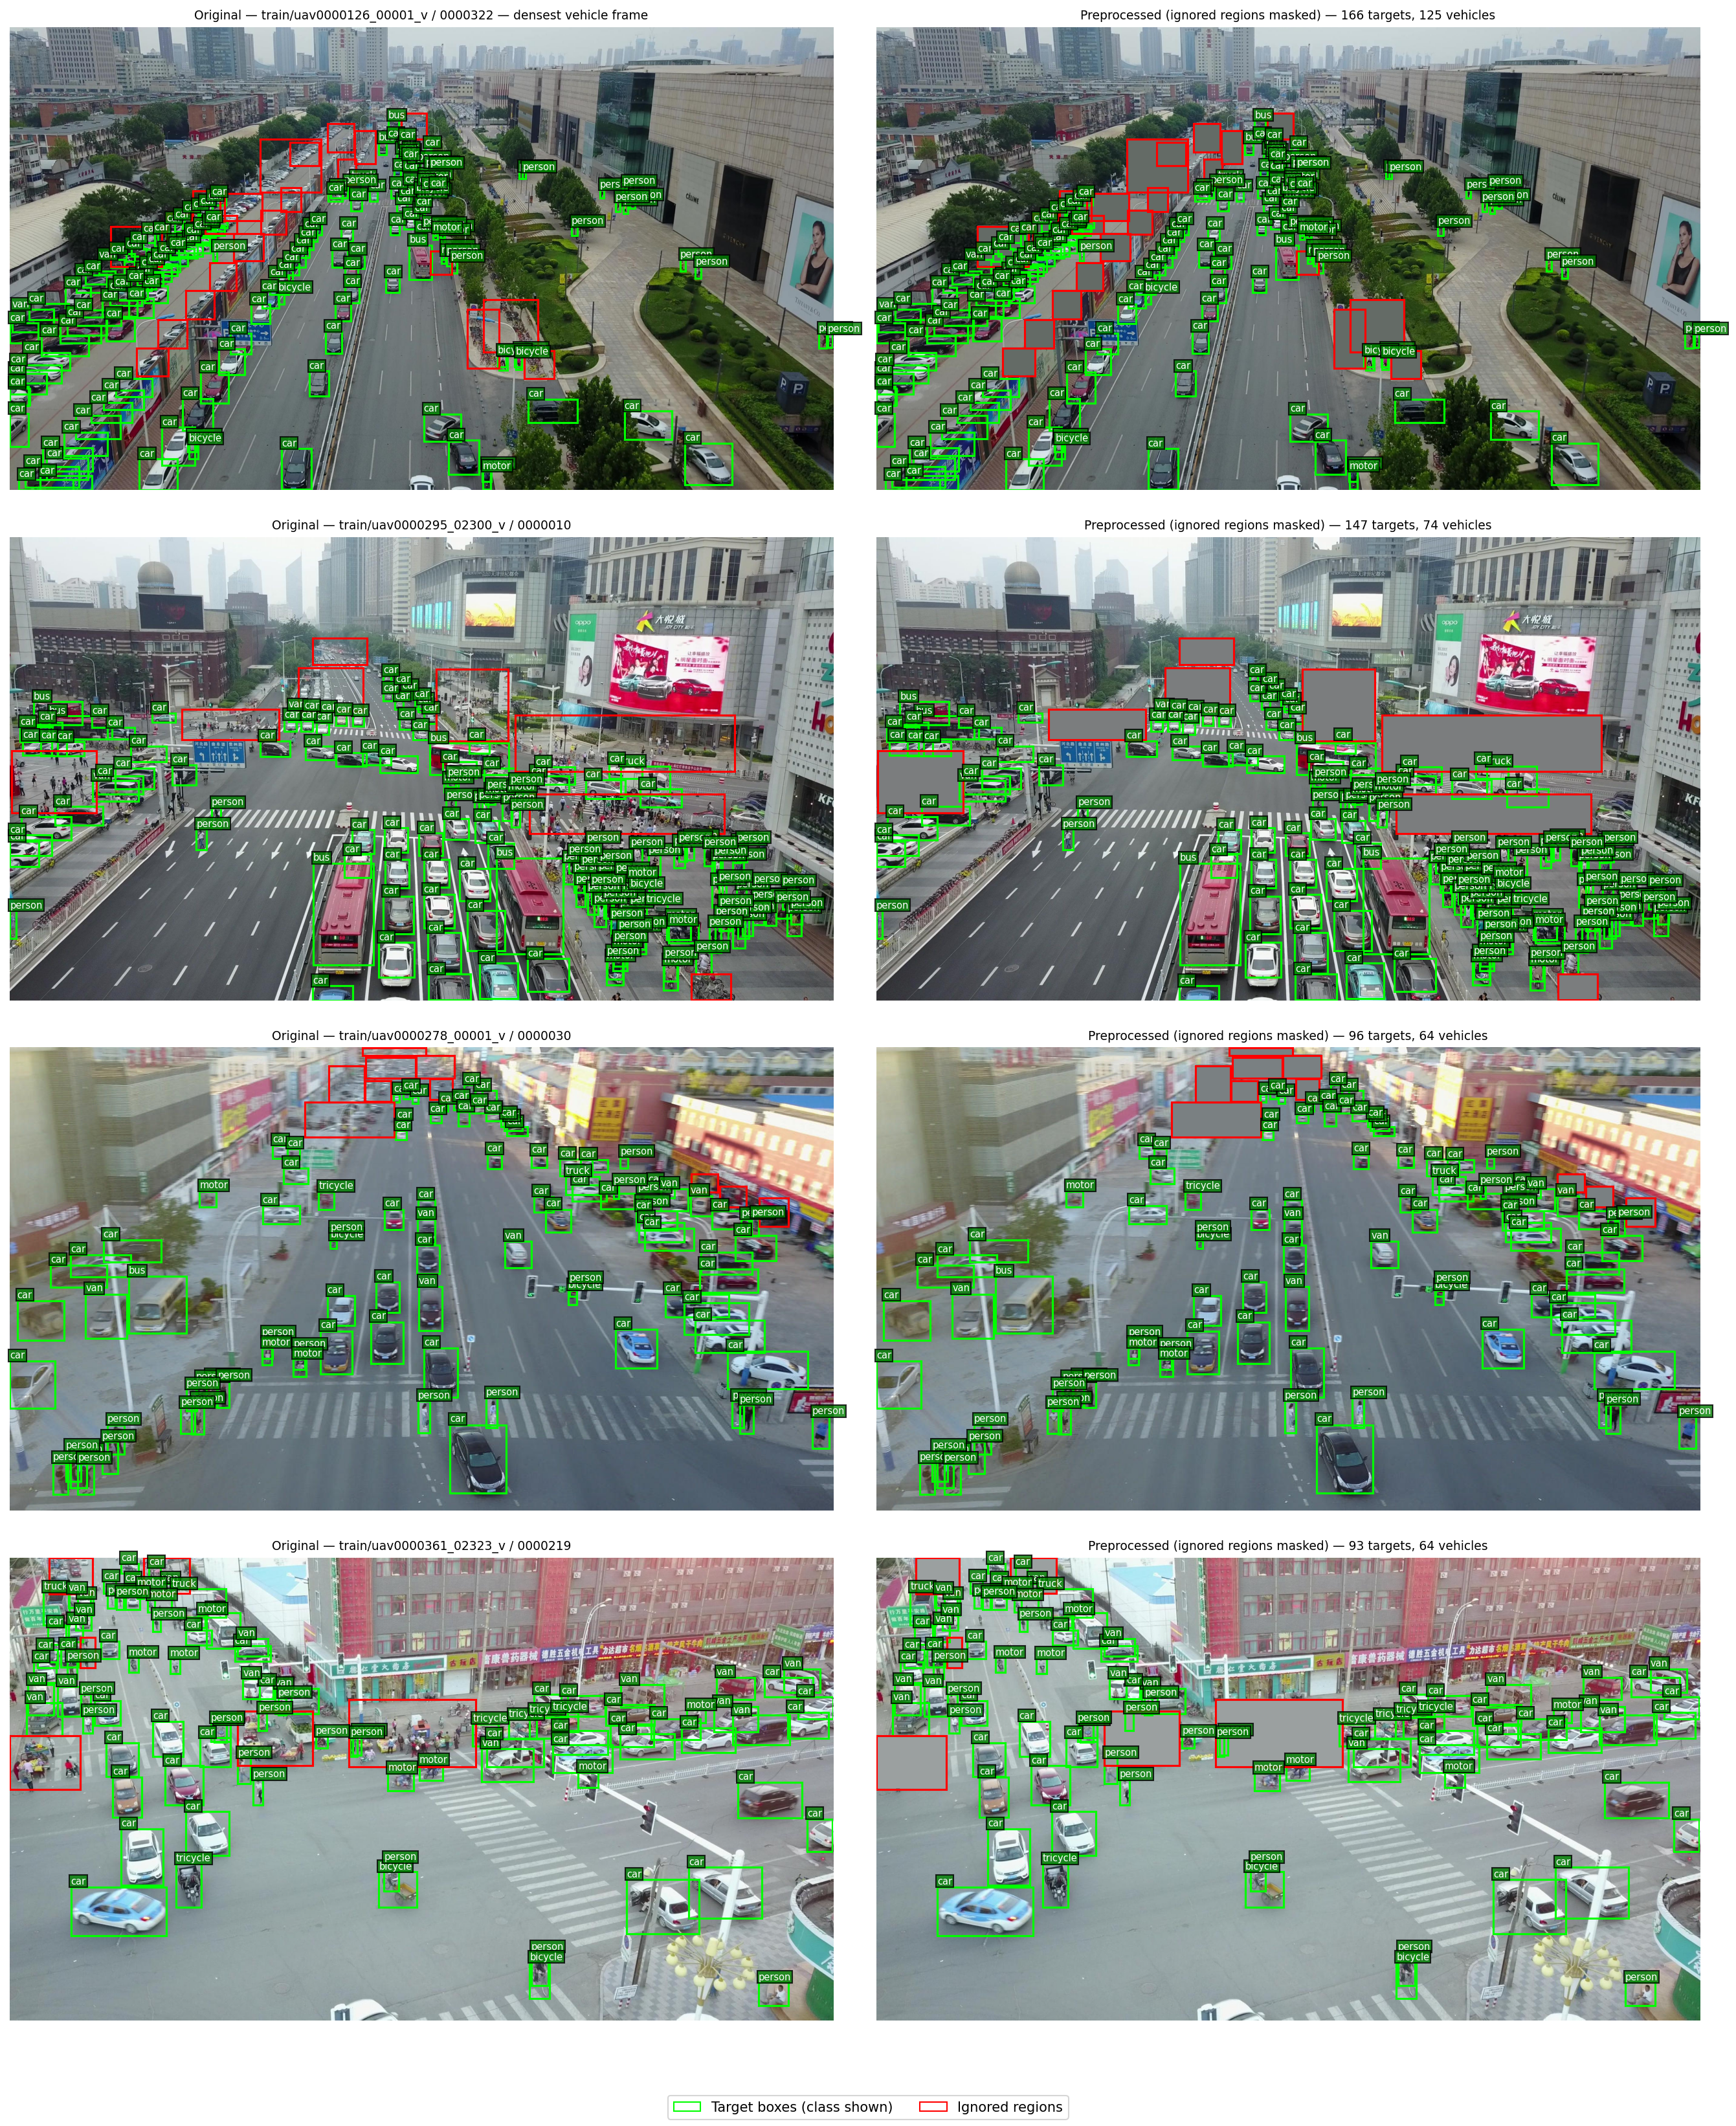

Saved verification figure to: /Users/romanpempus/Desktop/AI/hw_2/outputs/eda_gt_and_ignore_verification.png
Recreated exact split manifest: 50 train clips, 13 val clips -> /Users/romanpempus/Desktop/AI/hw_2/outputs/eda/sequence_split.csv


In [25]:
from pathlib import Path
from collections import defaultdict
import math

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
from PIL import Image


DATA_ROOT = Path("/content/data")
OUTPUT_PATH = Path(LOCAL_OUTPUT_DIR) / "eda_gt_and_ignore_verification.png"
CLASS_NAMES = ("person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor")
VEHICLE_CLASS_IDS = {2, 3, 4, 5, 6}


def _clamp(value, low, high):
    return min(max(float(value), low), high)


def _normalized_cxcywh_to_xyxy(cx, cy, w, h):
    # Clamp normalized values before converting to pixel coordinates.
    cx, cy = _clamp(cx, 0.0, 1.0), _clamp(cy, 0.0, 1.0)
    w, h = _clamp(w, 0.0, 1.0), _clamp(h, 0.0, 1.0)
    return (cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2)


def _read_annotation_files(paths):
    targets, ignores = [], []
    for path in sorted(set(paths)):
        with path.open("r", encoding="utf-8") as file:
            for line_number, line in enumerate(file, start=1):
                fields = line.split()
                if not fields:
                    continue
                try:
                    values = [float(value) for value in fields]
                except ValueError as exc:
                    raise ValueError(f"Invalid annotation in {path}:{line_number}") from exc

                if len(values) == 5:
                    raw_class_id = values[0]
                    class_id = int(raw_class_id)
                    if raw_class_id != class_id or not 0 <= class_id < len(CLASS_NAMES):
                        raise ValueError(
                            f"Invalid class id {raw_class_id} in {path}:{line_number}"
                        )
                    targets.append({
                        "class_id": class_id,
                        "xyxy": _normalized_cxcywh_to_xyxy(*values[1:]),
                    })
                elif len(values) == 4:
                    ignores.append(_normalized_cxcywh_to_xyxy(*values))
                else:
                    raise ValueError(
                        f"Expected 4 or 5 values in {path}:{line_number}; got {len(values)}"
                    )
    return targets, ignores


def _pixel_boxes(normalized_targets, normalized_ignores, width, height):
    targets, ignores = [], []

    for target in normalized_targets:
        x1, y1, x2, y2 = target["xyxy"]
        targets.append({
            "class_id": target["class_id"],
            "box": (
                _clamp(x1 * width, 0, width),
                _clamp(y1 * height, 0, height),
                _clamp(x2 * width, 0, width),
                _clamp(y2 * height, 0, height),
            ),
        })

    for x1, y1, x2, y2 in normalized_ignores:
        ignores.append((
            _clamp(x1 * width, 0, width),
            _clamp(y1 * height, 0, height),
            _clamp(x2 * width, 0, width),
            _clamp(y2 * height, 0, height),
        ))

    return targets, ignores


def preprocess_frame_and_boxes(image, target_boxes, ignore_boxes):
    """Mask ignored pixel-xyxy boxes; return the image and clamped boxes."""
    image = np.asarray(image).copy()
    if image.ndim != 3 or image.shape[2] != 3:
        raise ValueError("image must be an RGB array with shape (height, width, 3)")

    height, width = image.shape[:2]

    def clamp_box(box):
        x1, y1, x2, y2 = box
        x1, x2 = sorted((_clamp(x1, 0, width), _clamp(x2, 0, width)))
        y1, y2 = sorted((_clamp(y1, 0, height), _clamp(y2, 0, height)))
        return (x1, y1, x2, y2)

    clamped_targets = [
        {"class_id": target["class_id"], "box": clamp_box(target["box"])}
        for target in target_boxes
    ]
    clamped_ignores = [clamp_box(box) for box in ignore_boxes]

    mean_rgb = np.rint(image.astype(np.float32).mean(axis=(0, 1))).clip(0, 255).astype(np.uint8)
    for x1, y1, x2, y2 in clamped_ignores:
        left, top = int(math.floor(x1)), int(math.floor(y1))
        right, bottom = int(math.ceil(x2)), int(math.ceil(y2))
        image[top:bottom, left:right] = mean_rgb

    return image, clamped_targets, clamped_ignores


def _annotation_index(split_dir):
    """Index annotation files by clip/frame path and by basename."""
    folders = {"labels", "ignore", "annotations"}
    by_key, by_stem = defaultdict(list), defaultdict(list)

    for path in split_dir.rglob("*.txt"):
        parts = path.relative_to(split_dir).parts
        if not parts or parts[0] == "images":
            continue

        kind = parts[0] if parts[0] in {"labels", "ignore"} else "mixed"
        key_parts = parts[1:] if parts[0] in folders else parts
        key = Path(*key_parts).with_suffix("").as_posix()
        entry = (kind, path)
        by_key[key].append(entry)
        by_stem[path.stem].append(entry)

    return by_key, by_stem


def _find_annotation_files(image_rel, by_key, by_stem):
    key = image_rel.with_suffix("").as_posix()
    exact = list(by_key.get(key, []))
    selected = {path for _, path in exact}
    result = list(exact)

    # Support flat label/ignore folders when the basename identifies one file
    # of that type unambiguously.
    for kind in ("labels", "ignore", "mixed"):
        already_present = any(existing_kind == kind for existing_kind, _ in result)
        if already_present:
            continue
        candidates = [(candidate_kind, path)
                      for candidate_kind, path in by_stem.get(image_rel.stem, [])
                      if candidate_kind == kind and path not in selected]
        if len(candidates) == 1:
            result.extend(candidates)
            selected.add(candidates[0][1])

    return [path for _, path in result]


if not DATA_ROOT.is_dir():
    raise FileNotFoundError(f"Dataset directory not found: {DATA_ROOT}")

candidates = []
for split_dir in (DATA_ROOT / "train", DATA_ROOT / "val"):
    images_dir = split_dir / "images"
    if not images_dir.is_dir():
        continue

    by_key, by_stem = _annotation_index(split_dir)
    for image_path in sorted(
        p for p in images_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    ):
        image_rel = image_path.relative_to(images_dir)
        annotation_files = _find_annotation_files(image_rel, by_key, by_stem)
        if not annotation_files:
            continue

        targets, ignores = _read_annotation_files(annotation_files)
        if targets and ignores:
            candidates.append({
                "path": image_path,
                "clip": f"{split_dir.name}/{image_rel.parent.as_posix()}",
                "targets": targets,
                "ignores": ignores,
            })

if not candidates:
    raise RuntimeError(
        "No frames with both target objects and ignored regions were found. "
        "Check the dataset and annotation layout."
    )

# Keep one diverse, well-annotated candidate per clip.
by_clip = defaultdict(list)
for candidate in candidates:
    by_clip[candidate["clip"]].append(candidate)

best_per_clip = [
    max(
        clip_candidates,
        key=lambda c: (
            sum(t["class_id"] in VEHICLE_CLASS_IDS for t in c["targets"]),
            len(c["targets"]),
            len({t["class_id"] for t in c["targets"]}),
        ),
    )
    for clip_candidates in by_clip.values()
]

if len(best_per_clip) < 4:
    raise RuntimeError(
        f"Need eligible frames from at least 4 different clips; found {len(best_per_clip)}."
    )

dense_frame = max(
    best_per_clip,
    key=lambda c: (
        sum(t["class_id"] in VEHICLE_CLASS_IDS for t in c["targets"]),
        len(c["targets"]),
        len({t["class_id"] for t in c["targets"]}),
    ),
)
selected = [dense_frame]
remaining = [c for c in best_per_clip if c["clip"] != dense_frame["clip"]]

# Prefer clips adding new classes, then frames with varied object counts.
while len(selected) < 4:
    seen_classes = {
        t["class_id"] for frame in selected for t in frame["targets"]
    }
    selected.append(max(
        remaining,
        key=lambda c: (
            len({t["class_id"] for t in c["targets"]} - seen_classes),
            len({t["class_id"] for t in c["targets"]}),
            len(c["targets"]),
            c["clip"],
        ),
    ))
    remaining = [c for c in remaining if c["clip"] != selected[-1]["clip"]]

OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
fig, axes = plt.subplots(4, 2, figsize=(18, 22), dpi=150)

for row, (ax_original, ax_processed, frame) in enumerate(zip(axes[:, 0], axes[:, 1], selected)):
    with Image.open(frame["path"]) as source:
        original = np.asarray(source.convert("RGB"))

    height, width = original.shape[:2]
    targets, ignores = _pixel_boxes(
        frame["targets"], frame["ignores"], width, height
    )
    processed, targets, ignores = preprocess_frame_and_boxes(
        original, targets, ignores
    )

    for ax, image in ((ax_original, original), (ax_processed, processed)):
        ax.imshow(image)
        ax.axis("off")

        for target in targets:
            x1, y1, x2, y2 = target["box"]
            class_name = CLASS_NAMES[target["class_id"]]
            ax.add_patch(mpatches.Rectangle(
                (x1, y1), x2 - x1, y2 - y1,
                fill=False, edgecolor="lime", linewidth=1.5,
            ))
            ax.text(
                x1, max(0, y1 - 2), class_name,
                color="white", fontsize=7, va="bottom",
                bbox={"facecolor": "green", "alpha": 0.8, "pad": 1},
            )

        for x1, y1, x2, y2 in ignores:
            ax.add_patch(mpatches.Rectangle(
                (x1, y1), x2 - x1, y2 - y1,
                fill=False, edgecolor="red", linewidth=1.5,
            ))

    vehicle_count = sum(t["class_id"] in VEHICLE_CLASS_IDS for t in frame["targets"])
    dense_tag = " — densest vehicle frame" if frame is dense_frame else ""
    ax_original.set_title(
        f"Original — {frame['clip']} / {frame['path'].stem}{dense_tag}",
        fontsize=9,
    )
    ax_processed.set_title(
        f"Preprocessed (ignored regions masked) — "
        f"{len(targets)} targets, {vehicle_count} vehicles",
        fontsize=9,
    )

fig.legend(
    handles=[
        mpatches.Patch(facecolor="none", edgecolor="lime", label="Target boxes (class shown)"),
        mpatches.Patch(facecolor="none", edgecolor="red", label="Ignored regions"),
    ],
    loc="lower center",
    ncol=2,
    frameon=True,
)
fig.tight_layout(rect=(0, 0.035, 1, 1))
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
plt.figure(fig.number)
plt.savefig(OUTPUT_PATH, dpi=300, bbox_inches="tight")
plt.show()

verification_message = f"Saved verification figure to: {OUTPUT_PATH.resolve()}"
print(verification_message)
append_output_log(OUTPUT_LOG_DIR / "eda_verification.txt", verification_message)


import csv
import random

SPLIT_CSV = Path(LOCAL_OUTPUT_DIR) / "eda" / "sequence_split.csv"
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

all_rows = []
for split_name in ("train", "val"):
    split_root = DATA_ROOT / split_name
    img_root = split_root / "images" if (split_root / "images").is_dir() else split_root
    for img_path in sorted(p for p in img_root.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTS):
        rel = img_path.relative_to(img_root)
        clip_id = rel.parts[0] if len(rel.parts) > 1 else f"flat:{split_name}"
        all_rows.append((clip_id, split_name, img_path.stem, img_path.as_posix()))

clip_ids = sorted({row[0] for row in all_rows})
shuffled = clip_ids.copy()
random.Random(42).shuffle(shuffled)
val_count = min(len(clip_ids) - 1, max(1, round(len(clip_ids) * 0.2)))
val_clips = set(shuffled[:val_count])

SPLIT_CSV.parent.mkdir(parents=True, exist_ok=True)
with SPLIT_CSV.open("w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(("clip_id", "assigned_split", "source_split", "frame_id", "image_path"))
    for clip_id, source_split, frame_id, img_posix in all_rows:
        assigned = "val" if clip_id in val_clips else "train"
        writer.writerow((clip_id, assigned, source_split, frame_id, img_posix))

manifest_message = f"Recreated exact split manifest: {len(clip_ids) - len(val_clips)} train clips, {len(val_clips)} val clips -> {SPLIT_CSV}"
print(manifest_message)
append_output_log(OUTPUT_LOG_DIR / "eda_verification.txt", manifest_message)

## Two-Stage Detector: Faster R-CNN ResNet50-FPN-V2

In [5]:
!pip install -q torchmetrics pycocotools albumentations ultralytics

In [6]:
from __future__ import annotations

from collections import defaultdict
import csv
from dataclasses import dataclass
import math
import os
from pathlib import Path
import random
import re
import time
from typing import Any, Sequence

os.environ["NO_ALBUMENTATIONS_UPDATE"] = "1"

import albumentations as A
from albumentations.pytorch import ToTensorV2
import numpy as np
from PIL import Image
import torch
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch import Tensor
from torch.utils.data import DataLoader, Dataset
from torchmetrics.detection.mean_ap import MeanAveragePrecision
from torchvision.models.detection import (
    FasterRCNN_ResNet50_FPN_V2_Weights,
    fasterrcnn_resnet50_fpn_v2,
)
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

CLASS_NAMES = (
    "person",
    "bicycle",
    "car",
    "van",
    "truck",
    "tricycle",
    "bus",
    "motor",
)
IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
IMAGE_MEAN = (0.485, 0.456, 0.406)
IMAGE_STD = (0.229, 0.224, 0.225)
TRAILING_NUMBER = re.compile(r"-\d+$")
NUM_CLASSES = len(CLASS_NAMES) + 1

@dataclass(frozen=True)
class ImageRecord:
  image_path: Path
  source_split: str
  assigned_split: str
  clip_id: str
  frame_id: str

def project_root() -> Path:
  try:
    return Path(__file__).resolve().parents[2]
  except NameError:
    return Path.cwd()

def default_data_root() -> Path:
  colab_root = Path("/content/data")
  if colab_root.is_dir():
    return colab_root
  return project_root() / "toy_data"

def normalized_stem(stem: str) -> str:
  return TRAILING_NUMBER.sub("", stem)

def resolve_manifest_image(
    raw_path: str,
    source_split: str,
    data_root: Path,
    manifest_path: Path,
) -> Path | None:
  recorded_path = Path(raw_path).expanduser()
  candidates: list[Path] = []
  if recorded_path.is_absolute():
    candidates.append(recorded_path)
  else:
    candidates.extend(
        (manifest_path.parent / recorded_path, data_root / recorded_path)
    )

  parts = recorded_path.parts
  split_index = next(
      (index for index, part in enumerate(parts) if part == source_split),
      None,
  )
  if split_index is not None:
    candidates.append(
        data_root / source_split / Path(*parts[split_index + 1 :])
    )
  candidates.append(data_root / source_split / recorded_path.name)

  for candidate in candidates:
    if candidate.is_file() and candidate.suffix.lower() in IMAGE_SUFFIXES:
      return candidate.resolve()
  return None

def load_manifest_records(
    manifest_path: Path,
    data_root: Path,
) -> list[ImageRecord]:
  required_columns = {
      "clip_id",
      "assigned_split",
      "source_split",
      "frame_id",
      "image_path",
  }
  records: list[ImageRecord] = []
  with manifest_path.open(newline="", encoding="utf-8") as manifest:
    reader = csv.DictReader(manifest)
    if not reader.fieldnames or not required_columns.issubset(
        reader.fieldnames
    ):
      raise ValueError(
          "manifest must contain columns"
          f" {', '.join(sorted(required_columns))}"
      )
    for line_number, row in enumerate(reader, start=2):
      source_split = (row.get("source_split") or "").strip()
      assigned_split = (row.get("assigned_split") or "").strip().lower()
      clip_id = (row.get("clip_id") or "").strip()
      frame_id = (row.get("frame_id") or "").strip()
      raw_path = (row.get("image_path") or "").strip()
      if (
          source_split not in {"train", "val"}
          or assigned_split not in {"train", "val"}
          or not clip_id
          or not raw_path
      ):
        raise ValueError(
            f"{manifest_path}:{line_number}: invalid split manifest row"
        )
      image_path = resolve_manifest_image(
          raw_path, source_split, data_root, manifest_path
      )
      if image_path is None:
        raise ValueError(
            f"{manifest_path}:{line_number}: cannot resolve image"
            f" {raw_path!r} under data root {data_root}"
        )
      records.append(
          ImageRecord(
              image_path,
              source_split,
              assigned_split,
              clip_id,
              frame_id or image_path.stem,
          )
      )

  if not records:
    raise ValueError(f"manifest contains no image rows: {manifest_path}")
  if not any(record.assigned_split == "train" for record in records):
    raise ValueError("manifest has no training images")
  if not any(record.assigned_split == "val" for record in records):
    raise ValueError("manifest has no validation images")
  clip_splits: dict[str, set[str]] = defaultdict(set)
  for record in records:
    clip_splits[record.clip_id].add(record.assigned_split)
  leaking_clips = [
      clip for clip, splits in clip_splits.items() if len(splits) > 1
  ]
  if leaking_clips:
    raise ValueError(
        "manifest leaks clips across train/val: "
        + ", ".join(sorted(leaking_clips))
    )
  return records

def _image_root(split_root: Path) -> Path:
  candidate = split_root / "images"
  return candidate if candidate.is_dir() else split_root

def _scan_split(data_root: Path, split_name: str) -> list[ImageRecord]:
  split_root = data_root / split_name
  if not split_root.is_dir():
    raise FileNotFoundError(f"expected standard split directory: {split_root}")
  image_root = _image_root(split_root)
  image_paths = sorted(
      path
      for path in image_root.rglob("*")
      if path.is_file() and path.suffix.lower() in IMAGE_SUFFIXES
  )
  if not image_paths:
    raise FileNotFoundError(f"no image files found under {image_root}")

  records: list[ImageRecord] = []
  for image_path in image_paths:
    relative = image_path.relative_to(image_root)
    clip_id = (
        relative.parts[0] if len(relative.parts) > 1 else f"flat:{split_name}"
    )
    records.append(
        ImageRecord(
            image_path.resolve(),
            split_name,
            split_name,
            clip_id,
            image_path.stem,
        )
    )
  return records

def load_records(manifest: Path, data_root: Path) -> tuple[list[ImageRecord], str]:
  if manifest.is_file():
    records = load_manifest_records(manifest, data_root)
    return records, f"manifest: {manifest}"
  print(f"WARNING: manifest not found at {manifest}; scanning split folders.")

  records = _scan_split(data_root, "train") + _scan_split(data_root, "val")
  return records, f"scanned: {data_root / 'train'} and {data_root / 'val'}"

def clip_box(
    box: Sequence[float],
    image_width: int,
    image_height: int,
) -> list[float] | None:
  x1, y1, x2, y2 = box
  clipped = [
      min(max(float(x1), 0.0), float(image_width)),
      min(max(float(y1), 0.0), float(image_height)),
      min(max(float(x2), 0.0), float(image_width)),
      min(max(float(y2), 0.0), float(image_height)),
  ]
  if clipped[2] <= clipped[0] or clipped[3] <= clipped[1]:
    return None
  return clipped

def _annotation_boxes(
    annotation_path: Path,
    image_width: int,
    image_height: int,
) -> tuple[list[list[float]], list[int], list[list[float]]]:
  object_boxes: list[list[float]] = []
  object_labels: list[int] = []
  ignore_boxes: list[list[float]] = []
  try:
    rows = annotation_path.read_text(encoding="utf-8").splitlines()
  except OSError as error:
    raise OSError(
        f"could not read annotation {annotation_path}: {error}"
    ) from error

  for line_number, row in enumerate(rows, start=1):
    fields = row.split()
    if not fields:
      continue
    if len(fields) not in {4, 5}:
      raise ValueError(
          f"{annotation_path}:{line_number}: expected 4 ignore or 5 object"
          " values"
      )
    try:
      values = [float(field) for field in fields]
    except ValueError as error:
      raise ValueError(
          f"{annotation_path}:{line_number}: annotation values must be numeric"
      ) from error
    if not all(math.isfinite(value) for value in values):
      raise ValueError(
          f"{annotation_path}:{line_number}: values must be finite"
      )

    if len(values) == 5:
      raw_class, cx, cy, width, height = values
      class_id = int(raw_class)
      if raw_class != class_id or not 0 <= class_id < len(CLASS_NAMES):
        raise ValueError(
            f"{annotation_path}:{line_number}: class id must be in [0, 7]"
        )
    else:
      cx, cy, width, height = values
      class_id = -1
    if width <= 0 or height <= 0:
      raise ValueError(
          f"{annotation_path}:{line_number}: box width and height must be"
          " positive"
      )

    absolute_box = (
        (cx - width / 2) * image_width,
        (cy - height / 2) * image_height,
        (cx + width / 2) * image_width,
        (cy + height / 2) * image_height,
    )
    box = clip_box(absolute_box, image_width, image_height)
    if box is None:
      continue
    if class_id >= 0:
      object_boxes.append(box)
      object_labels.append(class_id + 1)
    else:
      ignore_boxes.append(box)
  return object_boxes, object_labels, ignore_boxes

def _flat_annotation_paths(split_root: Path) -> dict[str, list[Path]]:
  index: dict[str, list[Path]] = defaultdict(list)
  for path in sorted(split_root.rglob("*.txt")):
    if "labels" in path.parts or "ignore" in path.parts:
      continue
    index[normalized_stem(path.stem)].append(path)
  return index

def _find_annotation_paths(
    record: ImageRecord,
    split_root: Path,
    flat_index: dict[str, list[Path]],
) -> list[Path]:
  split_root = split_root.resolve()
  image_root = _image_root(split_root)
  image_path = record.image_path.resolve()
  try:
    relative_image = image_path.relative_to(image_root)
  except ValueError:
    relative_image = Path(image_path.name)

  labels_root = split_root / "labels"
  ignore_root = split_root / "ignore"
  if labels_root.is_dir() or ignore_root.is_dir():
    paths = []
    for root in (labels_root, ignore_root):
      candidate = root / relative_image.with_suffix(".txt")
      if candidate.is_file():
        paths.append(candidate)
    return paths

  candidates = flat_index.get(normalized_stem(image_path.stem), [])
  selected: set[Path] = set()
  for expected_values in (4, 5):
    matching = []
    empty = []
    for path in candidates:
      row_widths = {
          len(row.split())
          for row in path.read_text(encoding="utf-8").splitlines()
          if row.split()
      }
      if expected_values in row_widths:
        matching.append(path)
      elif not row_widths:
        empty.append(path)
    exact = [path for path in matching if path.stem == image_path.stem]
    if exact:
      selected.update(exact)
    elif matching:
      selected.update(matching)
    elif expected_values == 5:
      selected.update(path for path in empty if path.stem == image_path.stem)
  return sorted(selected)

class VisDroneDetectionDataset(Dataset[tuple[Tensor, dict[str, Tensor]]]):

  def __init__(
      self,
      records: Sequence[ImageRecord],
      data_root: Path,
      split: str,
      image_size: int = 512,
      mask_ignore_pixels: bool = True,
  ) -> None:
    self.records = [
        record for record in records if record.assigned_split == split
    ]
    if not self.records:
      raise ValueError(f"no {split} records were provided")
    self.data_root = data_root
    self.split = split
    self.image_size = image_size
    self.mask_ignore_pixels = mask_ignore_pixels
    self._split_roots = {
        source: (data_root / source).resolve()
        for source in {record.source_split for record in self.records}
    }
    self._flat_indexes = {
        source: _flat_annotation_paths(root)
        for source, root in self._split_roots.items()
        if not (root / "labels").is_dir() and not (root / "ignore").is_dir()
    }
    transforms: list[Any] = [A.Resize(height=image_size, width=image_size)]
    if split == "train":
      transforms.append(A.HorizontalFlip(p=0.5))
    transforms.extend(
        [
            A.Normalize(mean=IMAGE_MEAN, std=IMAGE_STD),
            ToTensorV2(),
        ]
    )
    self.transform = A.Compose(
        transforms,
        bbox_params=A.BboxParams(
            format="pascal_voc",
            label_fields=["labels", "iscrowd"],
            clip=True,
            filter_invalid_bboxes=True,
        ),
    )

  def __len__(self) -> int:
    return len(self.records)

  def __getitem__(self, index: int) -> tuple[Tensor, dict[str, Tensor]]:
    record = self.records[index]
    try:
      with Image.open(record.image_path) as source_image:
        image = np.asarray(source_image.convert("RGB")).copy()
    except (OSError, ValueError) as error:
      raise OSError(
          f"could not load image {record.image_path}: {error}"
      ) from error

    original_height, original_width = image.shape[:2]
    split_root = self._split_roots[record.source_split]
    paths = _find_annotation_paths(
        record,
        split_root,
        self._flat_indexes.get(record.source_split, {}),
    )
    object_boxes: list[list[float]] = []
    object_labels: list[int] = []
    ignore_boxes: list[list[float]] = []
    for annotation_path in paths:
      boxes, labels, ignores = _annotation_boxes(
          annotation_path, original_width, original_height
      )
      object_boxes.extend(boxes)
      object_labels.extend(labels)
      ignore_boxes.extend(ignores)

    if self.mask_ignore_pixels and ignore_boxes:
      mean_rgb = np.rint(
          image.astype(np.float32).mean(axis=(0, 1))
      ).clip(0, 255).astype(np.uint8)
      for x1, y1, x2, y2 in ignore_boxes:
        left, top = int(math.floor(x1)), int(math.floor(y1))
        right, bottom = int(math.ceil(x2)), int(math.ceil(y2))
        image[top:bottom, left:right] = mean_rgb

    combined_boxes = object_boxes + ignore_boxes
    combined_labels = object_labels + [1] * len(ignore_boxes)
    combined_crowd = [0] * len(object_boxes) + [1] * len(ignore_boxes)
    transformed = self.transform(
        image=image,
        bboxes=combined_boxes,
        labels=combined_labels,
        iscrowd=combined_crowd,
    )
    boxes = torch.as_tensor(
        transformed["bboxes"], dtype=torch.float32
    ).reshape(-1, 4)
    labels = torch.as_tensor(transformed["labels"], dtype=torch.int64)
    iscrowd = torch.as_tensor(transformed["iscrowd"], dtype=torch.int64)
    target: dict[str, Tensor] = {
        "boxes": boxes,
        "labels": labels,
        "iscrowd": iscrowd,
        "original_boxes": torch.tensor(
            object_boxes + ignore_boxes, dtype=torch.float32
        ).reshape(-1, 4),
        "original_labels": torch.tensor(
            object_labels + [1] * len(ignore_boxes), dtype=torch.int64
        ),
        "original_iscrowd": torch.tensor(
            [0] * len(object_boxes) + [1] * len(ignore_boxes), dtype=torch.int64
        ),
        "original_size": torch.tensor(
            [original_height, original_width], dtype=torch.int64
        ),
        "image_id": torch.tensor(index, dtype=torch.int64),
    }
    return transformed["image"], target

def detection_collate(
    batch: Sequence[tuple[Tensor, dict[str, Tensor]]],
) -> tuple[list[Tensor], list[dict[str, Tensor]]]:
  images, targets = zip(*batch)
  return list(images), list(targets)

def _model_target(target: dict[str, Tensor]) -> dict[str, Tensor]:
  keep = target["iscrowd"] == 0
  return {"boxes": target["boxes"][keep], "labels": target["labels"][keep]}

def choose_device(requested: str) -> torch.device:
  if requested != "auto":
    if requested == "cuda" and not torch.cuda.is_available():
      raise RuntimeError("--device cuda was selected but CUDA is unavailable")
    return torch.device(requested)
  return torch.device("cuda" if torch.cuda.is_available() else "cpu")

def build_model(
    device: torch.device,
    image_size: int,
    rpn_post_nms_topk: int,
    roi_batch_size: int,
    max_detections: int,
) -> torch.nn.Module:
  model = fasterrcnn_resnet50_fpn_v2(
      weights=FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT
  )
  classifier_features = model.roi_heads.box_predictor.cls_score.in_features
  model.roi_heads.box_predictor = FastRCNNPredictor(
      classifier_features, NUM_CLASSES
  )
  model.roi_heads.batch_size_per_image = roi_batch_size
  model.roi_heads.detections_per_img = max_detections
  for phase in ("training", "testing"):
    model.rpn._post_nms_top_n[phase] = rpn_post_nms_topk

  model.transform.image_mean = [0.0, 0.0, 0.0]
  model.transform.image_std = [1.0, 1.0, 1.0]
  model.transform.min_size = (image_size,)
  model.transform.max_size = image_size
  return model.to(device)

def _metric_target(target: dict[str, Tensor]) -> dict[str, Tensor]:
  original_boxes = target["original_boxes"]
  original_labels = target["original_labels"]
  original_iscrowd = target["original_iscrowd"]
  boxes = original_boxes[original_iscrowd == 0]
  labels = original_labels[original_iscrowd == 0]
  crowd_boxes = original_boxes[original_iscrowd == 1]
  if len(crowd_boxes):
    boxes = torch.cat((boxes, crowd_boxes.repeat(len(CLASS_NAMES), 1)))
    labels = torch.cat((
        labels,
        torch.arange(1, len(CLASS_NAMES) + 1, dtype=torch.int64).repeat_interleave(
            len(crowd_boxes)
        ),
    ))
    iscrowd = torch.cat((
        torch.zeros(len(original_boxes) - len(crowd_boxes), dtype=torch.int64),
        torch.ones(len(crowd_boxes) * len(CLASS_NAMES), dtype=torch.int64),
    ))
  else:
    iscrowd = torch.zeros(len(boxes), dtype=torch.int64)
  area = (boxes[:, 2] - boxes[:, 0]).clamp(min=0) * (
      boxes[:, 3] - boxes[:, 1]
  ).clamp(min=0)
  return {"boxes": boxes, "labels": labels, "iscrowd": iscrowd, "area": area}

def _original_resolution_prediction(
    prediction: dict[str, Tensor],
    target: dict[str, Tensor],
    image_size: int,
) -> dict[str, Tensor]:
  original_height, original_width = target["original_size"].tolist()
  scale = prediction["boxes"].new_tensor(
      [original_width / image_size, original_height / image_size] * 2
  )
  return {
      "boxes": prediction["boxes"] * scale,
      "scores": prediction["scores"],
      "labels": prediction["labels"],
  }

def _case_failure_counts(
    prediction: dict[str, Tensor],
    target: dict[str, Tensor],
    score_threshold: float = 0.5,
    iou_threshold: float = 0.5,
) -> tuple[int, int, list[str]]:
  gt_keep = target["original_iscrowd"].cpu() == 0
  gt_boxes = target["original_boxes"].cpu()[gt_keep]
  gt_labels = target["original_labels"].cpu()[gt_keep]
  pred_boxes = prediction["boxes"].detach().cpu()
  pred_labels = prediction["labels"].detach().cpu()
  scores = prediction["scores"].detach().cpu()
  matched = torch.zeros(len(gt_boxes), dtype=torch.bool)
  false_positives = 0

  for prediction_index in torch.argsort(scores, descending=True).tolist():
    if float(scores[prediction_index]) < score_threshold:
      continue
    eligible = (gt_labels == pred_labels[prediction_index]) & ~matched
    if not eligible.any():
      false_positives += 1
      continue
    candidate_indices = torch.where(eligible)[0]
    candidate_boxes = gt_boxes[candidate_indices]
    box = pred_boxes[prediction_index]
    top_left = torch.maximum(candidate_boxes[:, :2], box[:2])
    bottom_right = torch.minimum(candidate_boxes[:, 2:], box[2:])
    intersection = (bottom_right - top_left).clamp(min=0).prod(dim=1)
    candidate_area = (candidate_boxes[:, 2:] - candidate_boxes[:, :2]).clamp(min=0).prod(dim=1)
    box_area = (box[2:] - box[:2]).clamp(min=0).prod()
    iou = intersection / (candidate_area + box_area - intersection).clamp(min=1e-12)
    best_iou, best_local_index = iou.max(dim=0)
    if float(best_iou) >= iou_threshold:
      matched[candidate_indices[best_local_index]] = True
    else:
      false_positives += 1

  false_negatives = int((~matched).sum().item())
  reasons = []
  if false_positives:
    reasons.append(f"{false_positives} high-confidence false positive(s)")
  if false_negatives:
    reasons.append(f"{false_negatives} missed target(s)")
  return false_positives, false_negatives, reasons

@torch.inference_mode()
def evaluate(
    model: torch.nn.Module,
    loader: DataLoader[tuple[Tensor, dict[str, Tensor]]],
    device: torch.device,
    image_size: int,
) -> tuple[dict[str, float], list[dict[str, Any]]]:
  model.eval()
  metric = MeanAveragePrecision(
      box_format="xyxy",
      iou_type="bbox",
      iou_thresholds=[0.50 + index * 0.05 for index in range(10)],
      rec_thresholds=[index / 100 for index in range(101)],
      max_detection_thresholds=[1, 10, 100],
      class_metrics=False,
  )
  inference_seconds = 0.0
  image_count = 0
  case_records: list[dict[str, Any]] = []

  for images, targets in loader:
    model_images = [image.to(device) for image in images]
    if device.type == "cuda":
      torch.cuda.synchronize(device)
    started = time.perf_counter()
    predictions = model(model_images)
    if device.type == "cuda":
      torch.cuda.synchronize(device)
    inference_seconds += time.perf_counter() - started
    image_count += len(images)

    metric_predictions = []
    metric_targets = []
    for prediction, target in zip(predictions, targets):
      original_prediction = _original_resolution_prediction(
          prediction, target, image_size
      )
      metric_target = _metric_target(target)
      prediction_labels = original_prediction["labels"].detach().cpu()
      target_labels = metric_target["labels"]
      if (prediction_labels.numel() and (
          (prediction_labels < 1).any() or (prediction_labels >= NUM_CLASSES).any()
      )):
        raise ValueError(
            "prediction category IDs must match VisDrone COCO IDs 1 through "
            f"{NUM_CLASSES - 1}; found {prediction_labels.unique().tolist()}"
        )
      if target_labels.numel() and (
          (target_labels < 1).any() or (target_labels >= NUM_CLASSES).any()
      ):
        raise ValueError(
            "ground-truth category IDs must match VisDrone COCO IDs 1 through "
            f"{NUM_CLASSES - 1}; found {target_labels.unique().tolist()}"
        )
      metric_predictions.append({
          key: value.detach().cpu()
          for key, value in original_prediction.items()
      })
      metric_targets.append(metric_target)
      case_prediction = {
          key: value.detach().cpu()
          for key, value in original_prediction.items()
      }
      case_target = {
          key: value.detach().cpu() for key, value in target.items()
      }
      false_positives, false_negatives, reasons = _case_failure_counts(
          case_prediction, case_target
      )
      case_records.append({
          "prediction": case_prediction,
          "target": case_target,
          "record": loader.dataset.records[int(target["image_id"])],
          "false_positive_count": false_positives,
          "false_negative_count": false_negatives,
          "failure_score": false_positives + false_negatives,
          "reasons": reasons,
      })
    metric.update(metric_predictions, metric_targets)

  computed = metric.compute()
  average_seconds = inference_seconds / max(image_count, 1)
  coco_metric_keys = (
      "map",
      "map_50",
      "map_75",
      "map_small",
      "map_medium",
      "map_large",
      "mar_1",
      "mar_10",
      "mar_100",
      "mar_small",
      "mar_medium",
      "mar_large",
  )
  result = {key: float(computed[key].item()) for key in coco_metric_keys}
  if not math.isfinite(result["map"]) or result["map"] < 0:
    raise RuntimeError(
        "COCO mAP@[.50:.95] is undefined (TorchMetrics returned -1). "
        "Check that validation contains ground-truth objects and that the "
        "standard max_detection_thresholds [1, 10, 100] are preserved."
    )
  result.update({
      "inference_ms": average_seconds * 1000,
      "fps": 1 / average_seconds if average_seconds > 0 else float("inf"),
  })
  return result, case_records

def train_one_epoch(
    model: torch.nn.Module,
    loader: DataLoader[tuple[Tensor, dict[str, Tensor]]],
    optimizer: torch.optim.Optimizer,
    scaler: torch.amp.GradScaler | None,
    device: torch.device,
    epoch: int,
    epochs: int,
    max_grad_norm: float | None = None,
) -> float:
  model.train()
  total_loss = 0.0
  steps = 0
  use_amp = (device.type == "cuda") and (scaler is not None)

  for step, (images, targets) in enumerate(loader, start=1):
    model_images = [image.to(device) for image in images]
    model_targets = [
        {key: value.to(device) for key, value in _model_target(target).items()}
        for target in targets
    ]

    optimizer.zero_grad(set_to_none=True)

    with torch.amp.autocast("cuda", enabled=use_amp):
      loss_dict = model(model_images, model_targets)
      loss = sum(loss_value for loss_value in loss_dict.values())

    if not torch.isfinite(loss):
      raise FloatingPointError(
          f"non-finite training loss at epoch {epoch}, step {step}"
      )

    if use_amp and scaler is not None:
      scaler.scale(loss).backward()
      if max_grad_norm is not None:
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=max_grad_norm)
      scaler.step(optimizer)
      scaler.update()
    else:
      loss.backward()
      if max_grad_norm is not None:
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=max_grad_norm)
      optimizer.step()

    total_loss += float(loss.detach().item())
    steps += 1
    if step % 20 == 0 or step == len(loader):
      print(
          f"\rEpoch {epoch}/{epochs} | step {step}/{len(loader)} | loss"
          f" {float(loss.detach()):.4f}",
          end="",
          flush=True,
      )
  print()
  return total_loss / max(steps, 1)

In [ ]:
@tee_training_run("faster_rcnn_training.txt")
def main(config: dict[str, Any] | None = None) -> int:
  config = SHARED_CONFIG if config is None else config
  seed = int(config["seed"])
  frame_skip = int(config["frame_skip"])
  image_size = int(config["image_size"])
  epochs = int(config["epochs"])
  max_detections = int(config["max_detections"])
  batch_size = int(config["batch_size"])
  save_dir = Path(config["save_dir"]).expanduser().resolve()
  if frame_skip < 1:
    raise ValueError("SHARED_CONFIG['frame_skip'] must be at least 1")
  if epochs < 1:
    raise ValueError("SHARED_CONFIG['epochs'] must be at least 1")
  if max_detections < 10:
    raise ValueError("SHARED_CONFIG['max_detections'] must be at least 10")
  if batch_size < 1:
    raise ValueError("SHARED_CONFIG['batch_size'] must be at least 1")
  random.seed(seed)
  np.random.seed(seed)
  torch.manual_seed(seed)
  data_root = Path("/content/data")
  if not data_root.is_dir():
    data_root = default_data_root()
  data_root = data_root.expanduser().resolve()
  manifest = Path(config["manifest"]).expanduser()
  colab_manifest = Path("/content/outputs/eda/sequence_split.csv")
  if manifest == colab_manifest and not colab_manifest.is_file():
    manifest = Path("./outputs/eda/sequence_split.csv")
  manifest = manifest.resolve()
  save_dir.mkdir(parents=True, exist_ok=True)
  device = choose_device("auto")
  records, data_source = load_records(manifest, data_root)
  train_records = [record for record in records if record.assigned_split == "train"]
  val_records = [record for record in records if record.assigned_split == "val"]
  train_records = train_records[::frame_skip]
  val_records = val_records[::frame_skip]
  if not train_records:
    raise ValueError("no training images remain after frame skipping")
  if not val_records:
    raise ValueError("no validation images remain after frame skipping")
  train_clips = {record.clip_id for record in train_records}
  val_clips = {record.clip_id for record in val_records}
  leaking_clips = train_clips & val_clips
  if leaking_clips:
    raise ValueError(
        "manifest leaks clips across train/val after frame skipping: "
        + ", ".join(sorted(leaking_clips))
    )
  print(f"Data source: {data_source}")
  print(
      f"Train: {len(train_records)} frames / {len(train_clips)} clips; "
      f"Validation: {len(val_records)} frames / {len(val_clips)} clips"
  )
  print(f"Device: {device} | Image size: {image_size}px")
  selected_records = train_records + val_records
  mask_ignore_pixels = bool(config["mask_ignore_pixels"])
  train_dataset = VisDroneDetectionDataset(
      selected_records,
      data_root,
      "train",
      image_size=image_size,
      mask_ignore_pixels=mask_ignore_pixels,
  )
  val_dataset = VisDroneDetectionDataset(
      selected_records,
      data_root,
      "val",
      image_size=image_size,
      mask_ignore_pixels=mask_ignore_pixels,
  )
  loader_options = {
      "num_workers": 2,
      "collate_fn": detection_collate,
      "pin_memory": device.type == "cuda",
  }
  train_loader = DataLoader(
      train_dataset, batch_size=batch_size, shuffle=True, **loader_options
  )
  val_loader = DataLoader(
      val_dataset, batch_size=1, shuffle=False, **loader_options
  )
  model = build_model(
      device,
      image_size,
      rpn_post_nms_topk=1000,
      roi_batch_size=512,
      max_detections=max_detections,
  )
  optimizer = torch.optim.SGD(
      [parameter for parameter in model.parameters() if parameter.requires_grad],
      lr=0.005,
      momentum=0.9,
      weight_decay=0.0005,
  )
  scheduler = CosineAnnealingLR(optimizer, T_max=epochs)
  scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))
  best_map = float("-inf")
  epoch_map_history: list[float] = []
  global FASTER_RCNN_MAP_HISTORY
  FASTER_RCNN_MAP_HISTORY = epoch_map_history
  checkpoint_path = save_dir / "faster_rcnn_resnet50_fpn_v2_best.pth"
  for epoch in range(1, epochs + 1):
    epoch_started = time.perf_counter()
    learning_rate = float(optimizer.param_groups[0]["lr"])
    average_loss = train_one_epoch(
        model, train_loader, optimizer, scaler, device, epoch, epochs
    )
    metrics, _ = evaluate(
        model, val_loader, device, image_size
    )
    epoch_map_history.append(float(metrics["map"]))
    scheduler.step()
    saved_message = ""
    if metrics["map"] > best_map:
      best_map = metrics["map"]
      torch.save(
          {
              "epoch": epoch,
              "model_state_dict": model.state_dict(),
              "optimizer_state_dict": optimizer.state_dict(),
              "metrics": metrics,
              "SHARED_CONFIG": dict(config),
          },
          checkpoint_path,
      )
      saved_message = f" | saved best checkpoint: {checkpoint_path}"
    print(
        f"Epoch {epoch}/{epochs} | loss={average_loss:.4f} | "
        f"lr={learning_rate:.6g} | "
        f"mAP@[0.50:0.95]={metrics['map']:.4f} | "
        f"AP50={metrics['map_50']:.4f} | AP75={metrics['map_75']:.4f} | "
        f"AP_small={metrics['map_small']:.4f} | "
        f"AP_medium={metrics['map_medium']:.4f} | AP_large={metrics['map_large']:.4f} | "
        f"AR@1={metrics['mar_1']:.4f} | AR@10={metrics['mar_10']:.4f} | "
        f"AR@100={metrics['mar_100']:.4f} | "
        f"AR_small={metrics['mar_small']:.4f} | "
        f"AR_medium={metrics['mar_medium']:.4f} | AR_large={metrics['mar_large']:.4f} | "
        f"inference_ms={metrics['inference_ms']:.2f} | "
        f"fps={metrics['fps']:.1f} | "
        f"epoch_time={time.perf_counter() - epoch_started:.1f}s"
        f"{saved_message}"
    )
  print(f"Training complete. Best mAP={best_map:.4f}; checkpoint: {checkpoint_path}")
  download_checkpoint(checkpoint_path)
  return 0

# 1. Ensure save_dir points to Colab's local outputs folder
SHARED_CONFIG["save_dir"] = "./outputs/checkpoints"

main(SHARED_CONFIG)



Data source: scanned: /content/data/train and /content/data/val
Train: 692 frames / 56 clips; Validation: 82 frames / 7 clips
Device: cuda | Image size: 448px
Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


100%|##########| 167M/167M [00:01<00:00, 172MB/s] 


Epoch 1/3 | step 22/22 | loss 1.6756


/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Encountered more than 100 detections in a single image. This means that certain detections with the lowest scores will be ignored, that may have an undesirable impact on performance. Please consider adjusting the `max_detection_threshold` to suit your use case. To disable this warning, set attribute class `warn_on_many_detections=False`, after initializing the metric.
  warnings.warn(*args, **kwargs)


Epoch 1/3 | loss=2.3744 | lr=0.005 | mAP@[0.50:0.95]=0.0270 | AP50=0.0717 | AP75=0.0153 | AP_small=0.0117 | AP_medium=0.0235 | AP_large=0.0836 | AR@1=0.0059 | AR@10=0.0381 | AR@100=0.0777 | AR_small=0.0466 | AR_medium=0.0742 | AR_large=0.1539 | inference_ms=83.15 | fps=12.0 | epoch_time=73.9s | saved best checkpoint: /content/outputs/checkpoints/faster_rcnn_resnet50_fpn_v2_best.pth
Epoch 2/3 | step 22/22 | loss 1.4917
Epoch 2/3 | loss=1.5158 | lr=0.00375 | mAP@[0.50:0.95]=0.0405 | AP50=0.0929 | AP75=0.0339 | AP_small=0.0202 | AP_medium=0.0370 | AP_large=0.0929 | AR@1=0.0101 | AR@10=0.0451 | AR@100=0.0742 | AR_small=0.0480 | AR_medium=0.0714 | AR_large=0.1218 | inference_ms=86.56 | fps=11.6 | epoch_time=68.7s | saved best checkpoint: /content/outputs/checkpoints/faster_rcnn_resnet50_fpn_v2_best.pth
Epoch 3/3 | step 22/22 | loss 1.1818
Epoch 3/3 | loss=1.3603 | lr=0.00125 | mAP@[0.50:0.95]=0.0434 | AP50=0.1014 | AP75=0.0310 | AP_small=0.0202 | AP_medium=0.0380 | AP_large=0.1062 | AR@1=0.

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Transferring faster_rcnn_resnet50_fpn_v2_best.pth to Mac Downloads folder...


NameError: name 'files' is not defined

## One-Stage Anchor-Based Detector: RetinaNet ResNet50-FPN-V2

In [8]:
from torchvision.models.detection import (
    RetinaNet_ResNet50_FPN_V2_Weights,
    retinanet_resnet50_fpn_v2,
)
from torchvision.models.detection.anchor_utils import AnchorGenerator
from torchvision.models.detection.retinanet import (
    RetinaNetClassificationHead,
    RetinaNetHead,
)
from torchvision.ops import sigmoid_focal_loss
import pandas as pd

class ConfigurableRetinaNetClassificationHead(RetinaNetClassificationHead):
    def __init__(
        self,
        in_channels: int,
        num_anchors: int,
        num_classes: int,
        prior_probability: float = 0.01,
        focal_alpha: float = 0.25,
        focal_gamma: float = 2.0,
    ) -> None:
        super().__init__(
            in_channels=in_channels,
            num_anchors=num_anchors,
            num_classes=num_classes,
            prior_probability=prior_probability,
        )
        self.focal_alpha = focal_alpha
        self.focal_gamma = focal_gamma
    def compute_loss(self, targets, head_outputs, matched_idxs):
        losses = []
        for targets_per_image, logits, matched in zip(
            targets, head_outputs["cls_logits"], matched_idxs
        ):
            foreground = matched >= 0
            num_foreground = int(foreground.sum().item())
            class_targets = torch.zeros_like(logits)
            class_targets[
                foreground,
                targets_per_image["labels"][matched[foreground]],
            ] = 1.0
            valid = matched != self.BETWEEN_THRESHOLDS
            losses.append(
                sigmoid_focal_loss(
                    logits[valid],
                    class_targets[valid],
                    alpha=self.focal_alpha,
                    gamma=self.focal_gamma,
                    reduction="sum",
                )
                / max(1, num_foreground)
            )
        return torch.stack(losses).sum() / len(targets)

def build_retinanet_model(
    device: torch.device,
    image_size: int,
    max_detections: int,
    anchor_sizes: Sequence[Sequence[int]] | None = None,
    prior_prob: float = 0.01,
    focal_alpha: float = 0.25,
    focal_gamma: float = 2.0,
) -> torch.nn.Module:
    model = retinanet_resnet50_fpn_v2(
        weights=RetinaNet_ResNet50_FPN_V2_Weights.DEFAULT
    )
    pretrained_regression_head = model.head.regression_head
    if anchor_sizes is not None:
        normalized_sizes = tuple(
            tuple(int(size) for size in level) for level in anchor_sizes
        )
        model.anchor_generator = AnchorGenerator(
            sizes=normalized_sizes,
            aspect_ratios=((0.5, 1.0, 2.0),) * len(normalized_sizes),
        )
    num_anchors = model.anchor_generator.num_anchors_per_location()[0]
    model.head = RetinaNetHead(
        in_channels=model.backbone.out_channels,
        num_anchors=num_anchors,
        num_classes=NUM_CLASSES,
    )
    pretrained_num_anchors = pretrained_regression_head.bbox_reg.out_channels // 4
    if pretrained_num_anchors == num_anchors:
        model.head.regression_head = pretrained_regression_head
    model.head.classification_head = ConfigurableRetinaNetClassificationHead(
        in_channels=model.backbone.out_channels,
        num_anchors=num_anchors,
        num_classes=NUM_CLASSES,
        prior_probability=prior_prob,
        focal_alpha=focal_alpha,
        focal_gamma=focal_gamma,
    )
    model.detections_per_img = max_detections
    model.transform.image_mean = [0.0, 0.0, 0.0]
    model.transform.image_std = [1.0, 1.0, 1.0]
    model.transform.min_size = (image_size,)
    model.transform.max_size = image_size
    return model.to(device)

SMALL_RETINANET_ANCHORS = (
    (8, 10, 13),
    (16, 20, 25),
    (32, 40, 51),
    (64, 81, 102),
    (128, 161, 203),
)
EXPERIMENT_CONFIGS: dict[str, dict[str, Any]] = {
    "baseline": {
        "anchor_sizes": None,
        "lr": 0.0025,
        "focal_alpha": 0.25,
        "focal_gamma": 2.0,
        "warmup_cosine": False,
    },
    "exp1_small_anchors": {
        "anchor_sizes": SMALL_RETINANET_ANCHORS,
        "lr": 0.0025,
        "focal_alpha": 0.25,
        "focal_gamma": 2.0,
        "warmup_cosine": False,
    },
    "exp2_focal_lr": {
        "anchor_sizes": SMALL_RETINANET_ANCHORS,
        "lr": 0.001,
        "focal_alpha": 0.5,
        "focal_gamma": 2.5,
        "warmup_cosine": True,
    },
}

def _retinanet_data_loaders(
    config: dict[str, Any],
    device: torch.device,
    sample_size: int | None = 50,
) -> tuple[DataLoader, DataLoader]:
    data_root = Path("/content/data")
    if not data_root.is_dir():
        data_root = default_data_root()
    data_root = data_root.expanduser().resolve()
    manifest = Path(config["manifest"]).expanduser()
    colab_manifest = Path("/content/outputs/eda/sequence_split.csv")
    if manifest == colab_manifest and not colab_manifest.is_file():
        manifest = Path("./outputs/eda/sequence_split.csv")
    records, data_source = load_records(manifest.resolve(), data_root)
    frame_skip = int(config["frame_skip"])
    if frame_skip < 1:
        raise ValueError("SHARED_CONFIG['frame_skip'] must be at least 1")
    train_records = [
        record for record in records if record.assigned_split == "train"
    ][::frame_skip]
    val_records = [
        record for record in records if record.assigned_split == "val"
    ][::frame_skip]
    if sample_size is not None:
        if sample_size < 1:
            raise ValueError("sample_size must be at least 1 or None")
        sample_count = min(sample_size, len(val_records))
        val_records = random.Random(int(config["seed"])).sample(
            val_records, sample_count
        )
    if not train_records:
        raise ValueError("no training images remain after frame skipping")
    if not val_records:
        raise ValueError("no validation images remain after frame skipping")
    if {record.clip_id for record in train_records} & {
        record.clip_id for record in val_records
    }:
        raise ValueError("manifest leaks clips across train/val")
    selected_records = train_records + val_records
    mask_ignore_pixels = bool(config["mask_ignore_pixels"])
    image_size = int(config["image_size"])
    train_dataset = VisDroneDetectionDataset(
        selected_records,
        data_root,
        "train",
        image_size=image_size,
        mask_ignore_pixels=mask_ignore_pixels,
    )
    val_dataset = VisDroneDetectionDataset(
        selected_records,
        data_root,
        "val",
        image_size=image_size,
        mask_ignore_pixels=mask_ignore_pixels,
    )
    loader_options = {
        "num_workers": 2,
        "collate_fn": detection_collate,
        "pin_memory": device.type == "cuda",
    }
    print(
        f"Data source: {data_source} | train={len(train_dataset)} | "
        f"validation={len(val_dataset)}"
    )
    return (
        DataLoader(
            train_dataset,
            batch_size=int(config["batch_size"]),
            shuffle=True,
            **loader_options,
        ),
        DataLoader(val_dataset, batch_size=1, shuffle=False, **loader_options),
    )

@tee_training_run("retinanet_training.txt")
def run_retinanet_experiment(
    exp_name: str,
    exp_cfg: dict[str, Any],
    config: dict[str, Any] = SHARED_CONFIG,
) -> dict[str, Any]:
    if exp_name not in EXPERIMENT_CONFIGS:
        raise ValueError(
            f"unknown RetinaNet experiment {exp_name!r}; expected one of "
            f"{', '.join(EXPERIMENT_CONFIGS)}"
        )
    exp_cfg = {**EXPERIMENT_CONFIGS[exp_name], **exp_cfg}
    seed = int(config["seed"])
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    device = choose_device("auto")
    train_loader, val_loader = _retinanet_data_loaders(
        config, device, sample_size=None
    )
    epochs = int(config["epochs"])
    if epochs < 1:
        raise ValueError("SHARED_CONFIG['epochs'] must be at least 1")
    image_size = int(config["image_size"])
    max_detections = int(config["max_detections"])
    model = build_retinanet_model(
        device=device,
        image_size=image_size,
        max_detections=max_detections,
        anchor_sizes=exp_cfg.get("anchor_sizes"),
        prior_prob=float(exp_cfg.get("prior_prob", 0.01)),
        focal_alpha=float(exp_cfg["focal_alpha"]),
        focal_gamma=float(exp_cfg["focal_gamma"]),
    )
    optimizer = torch.optim.SGD(
        [parameter for parameter in model.parameters() if parameter.requires_grad],
        lr=float(exp_cfg["lr"]),
        momentum=0.9,
        weight_decay=0.0005,
    )
    if exp_cfg.get("warmup_cosine", False):
        warmup_epochs = min(2, max(1, epochs // 5))
        warmup = torch.optim.lr_scheduler.LinearLR(
            optimizer, start_factor=0.1, total_iters=warmup_epochs
        )
        cosine = CosineAnnealingLR(
            optimizer, T_max=max(1, epochs - warmup_epochs)
        )
        scheduler = torch.optim.lr_scheduler.SequentialLR(
            optimizer,
            schedulers=[warmup, cosine],
            milestones=[warmup_epochs],
        )
    else:
        scheduler = CosineAnnealingLR(optimizer, T_max=epochs)
    scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))
    save_dir = Path(config["save_dir"]).expanduser()
    save_dir.mkdir(parents=True, exist_ok=True)
    checkpoint_path = save_dir / f"retinanet_{exp_name}_best.pth"
    best_map = float("-inf")
    best_metrics: dict[str, float] = {}
    epoch_map_history: list[float] = []
    for epoch in range(1, epochs + 1):
        epoch_started = time.perf_counter()
        learning_rate = float(optimizer.param_groups[0]["lr"])
        average_loss = train_one_epoch(
            model,
            train_loader,
            optimizer,
            scaler,
            device,
            epoch,
            epochs,
            max_grad_norm=10.0,
        )
        metrics, _ = evaluate(
            model, val_loader, device, image_size
        )
        epoch_map_history.append(float(metrics["map"]))
        scheduler.step()
        if metrics["map"] > best_map:
            best_map = metrics["map"]
            best_metrics = dict(metrics)
            torch.save(
                {
                    "epoch": epoch,
                    "model_state_dict": model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "metrics": metrics,
                    "exp_cfg": dict(exp_cfg),
                    "SHARED_CONFIG": dict(config),
                },
                checkpoint_path,
            )
        print(
            f"[{exp_name}] Epoch {epoch}/{epochs} | "
            f"loss={average_loss:.4f} | "
            f"lr={learning_rate:.6g} | "
            f"mAP@[0.50:0.95]={metrics['map']:.4f} | "
            f"AP50={metrics['map_50']:.4f} | AP75={metrics['map_75']:.4f} | "
            f"AP_small={metrics['map_small']:.4f} | "
            f"AP_medium={metrics['map_medium']:.4f} | AP_large={metrics['map_large']:.4f} | "
            f"AR@1={metrics['mar_1']:.4f} | AR@10={metrics['mar_10']:.4f} | "
            f"AR@100={metrics['mar_100']:.4f} | "
            f"AR_small={metrics['mar_small']:.4f} | "
            f"AR_medium={metrics['mar_medium']:.4f} | AR_large={metrics['mar_large']:.4f} | "
            f"inference_ms={metrics['inference_ms']:.2f} | "
            f"fps={metrics['fps']:.1f} | "
            f"epoch_time={time.perf_counter() - epoch_started:.1f}s"
        )
    download_checkpoint(checkpoint_path)
    return {
        "model_family": "RetinaNet ResNet50-FPN-V2",
        "experiment": exp_name,
        "best_map": best_map,
        "ap50": best_metrics.get("map_50", float("nan")),
        "ap_small": best_metrics.get("map_small", float("nan")),
        "inference_ms": best_metrics.get("inference_ms", float("nan")),
        "fps": best_metrics.get("fps", float("nan")),
        "checkpoint_path": str(checkpoint_path),
        "epoch_map_history": epoch_map_history,
    }


# actual training 

In [11]:
# Execute the RetinaNet baseline experiment
retinanet_baseline_results = run_retinanet_experiment(
    exp_name="baseline",
    exp_cfg={},
    config=SHARED_CONFIG
)

Data source: scanned: /content/data/train and /content/data/val | train=692 | validation=82
Downloading: "https://download.pytorch.org/models/retinanet_resnet50_fpn_v2_coco-5905b1c5.pth" to /root/.cache/torch/hub/checkpoints/retinanet_resnet50_fpn_v2_coco-5905b1c5.pth


100%|##########| 146M/146M [00:01<00:00, 122MB/s] 


Epoch 1/3 | step 22/22 | loss 1.4922
[baseline] Epoch 1/3 | loss=1.6254 | lr=0.0025 | mAP@[0.50:0.95]=0.0004 | AP50=0.0013 | AP75=0.0002 | AP_small=0.0000 | AP_medium=0.0004 | AP_large=0.0014 | AR@1=0.0007 | AR@10=0.0024 | AR@100=0.0133 | AR_small=0.0006 | AR_medium=0.0126 | AR_large=0.0239 | inference_ms=55.95 | fps=17.9 | epoch_time=58.0s
Epoch 2/3 | step 22/22 | loss 1.1284
[baseline] Epoch 2/3 | loss=1.2587 | lr=0.001875 | mAP@[0.50:0.95]=0.0020 | AP50=0.0056 | AP75=0.0011 | AP_small=0.0006 | AP_medium=0.0030 | AP_large=0.0048 | AR@1=0.0033 | AR@10=0.0096 | AR@100=0.0293 | AR_small=0.0044 | AR_medium=0.0237 | AR_large=0.0698 | inference_ms=63.84 | fps=15.7 | epoch_time=59.4s
Epoch 3/3 | step 22/22 | loss 1.0489
[baseline] Epoch 3/3 | loss=1.1069 | lr=0.000625 | mAP@[0.50:0.95]=0.0032 | AP50=0.0088 | AP75=0.0018 | AP_small=0.0007 | AP_medium=0.0033 | AP_large=0.0098 | AR@1=0.0067 | AR@10=0.0195 | AR@100=0.0430 | AR_small=0.0057 | AR_medium=0.0317 | AR_large=0.1075 | inference_ms=55.

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# saving chekpoints

In [15]:

# 2. Download the saved checkpoint path returned by the experiment
checkpoint_path = retinanet_baseline_results["checkpoint_path"]
print(f"Checkpoint saved at: {checkpoint_path}")

download_checkpoint(checkpoint_path)

Checkpoint saved at: outputs/checkpoints/retinanet_baseline_best.pth


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## One-Stage Anchor-Free Detector: Ultralytics YOLO

This section exports the shared VisDrone manifest to Ultralytics YOLO format, masks ignored regions, and evaluates each best checkpoint with the same TorchMetrics COCO metric contract used above.

In [17]:
import json
import random
import shutil
import time

import numpy as np
import torch
from PIL import Image
from torchmetrics.detection.mean_ap import MeanAveragePrecision

YOLO_EXPERIMENT_CONFIGS: dict[str, dict[str, Any]] = {
    'baseline': {
        'model': 'yolov8n.pt',
        'imgsz': 448,
        'box': 7.5,
        'cls': 0.5,
        'dfl': 1.5,
    },
    'exp1_high_res': {
        'model': 'yolov8n.pt',
        'imgsz': 448,
        'box': 7.5,
        'cls': 0.5,
        'dfl': 1.5,
    },
    'exp2_loss_tuning': {
        'model': 'yolov8n.pt',
        'imgsz': 448,
        'box': 10.0,
        'cls': 0.5,
        'dfl': 2.5,
    },
}


def prepare_yolo_dataset(
    config: dict[str, Any] = SHARED_CONFIG,
    data_root: str | Path | None = None,
    output_dir: str | Path | None = None,
) -> dict[str, Any]:
    """Export manifest records and annotations to Ultralytics YOLO format."""
    root = Path(data_root) if data_root is not None else Path(config.get('data_root', default_data_root()))
    root = root.expanduser().resolve()
    manifest = Path(config['manifest']).expanduser()
    colab_manifest = Path('/content/outputs/eda/sequence_split.csv')
    if manifest == colab_manifest and not colab_manifest.is_file():
        manifest = Path('./outputs/eda/sequence_split.csv')
    records, source = load_records(manifest.resolve(), root)
    frame_skip = int(config['frame_skip'])
    image_size = int(config['image_size'])
    if frame_skip < 1:
        raise ValueError("SHARED_CONFIG['frame_skip'] must be at least 1")
    train_records = [r for r in records if r.assigned_split == 'train'][::frame_skip]
    val_records = [r for r in records if r.assigned_split == 'val'][::frame_skip]
    if not train_records or not val_records:
        raise ValueError('YOLO export requires non-empty train and validation splits')
    if {r.clip_id for r in train_records} & {r.clip_id for r in val_records}:
        raise ValueError('manifest leaks clips across train/val')

    destination = (
        Path(output_dir)
        if output_dir is not None
        else Path(config['save_dir']).expanduser() / 'visdrone_yolo'
    ).resolve()
    split_dirs: dict[str, tuple[Path, Path]] = {}
    for split in ('train', 'val'):
        image_dir = destination / 'images' / split
        label_dir = destination / 'labels' / split
        # These four directories are generated output and are rebuilt on each export.
        for generated_dir in (image_dir, label_dir):
            if generated_dir.exists():
                shutil.rmtree(generated_dir)
            generated_dir.mkdir(parents=True, exist_ok=True)
        split_dirs[split] = (image_dir, label_dir)

    records_by_split = {'train': train_records, 'val': val_records}
    split_roots = {
        source_split: (root / source_split).resolve()
        for source_split in {r.source_split for r in train_records + val_records}
    }
    flat_indexes = {
        source_split: _flat_annotation_paths(split_root)
        for source_split, split_root in split_roots.items()
        if not (split_root / 'labels').is_dir() and not (split_root / 'ignore').is_dir()
    }
    exported: dict[str, list[tuple[Path, Path]]] = {'train': [], 'val': []}
    mask_ignore_pixels = bool(config.get('mask_ignore_pixels', True))

    for split, split_records in records_by_split.items():
        image_dir, label_dir = split_dirs[split]
        for index, record in enumerate(split_records):
            try:
                with Image.open(record.image_path) as source_image:
                    image = np.asarray(source_image.convert('RGB')).copy()
            except (OSError, ValueError) as error:
                raise OSError(f'could not load image {record.image_path}: {error}') from error
            height, width = image.shape[:2]
            annotation_paths = _find_annotation_paths(
                record,
                split_roots[record.source_split],
                flat_indexes.get(record.source_split, {}),
            )
            boxes: list[list[float]] = []
            labels: list[int] = []
            ignore_boxes: list[list[float]] = []
            for annotation_path in annotation_paths:
                object_boxes, object_labels, ignores = _annotation_boxes(
                    annotation_path, width, height
                )
                boxes.extend(object_boxes)
                labels.extend(object_labels)
                ignore_boxes.extend(ignores)
            if mask_ignore_pixels and ignore_boxes:
                mean_rgb = np.rint(image.astype(np.float32).mean(axis=(0, 1))).clip(0, 255).astype(np.uint8)
                for x1, y1, x2, y2 in ignore_boxes:
                    image[int(np.floor(y1)):int(np.ceil(y2)), int(np.floor(x1)):int(np.ceil(x2))] = mean_rgb

            filename = f'{index:08d}{record.image_path.suffix.lower()}'
            image_path = image_dir / filename
            label_path = label_dir / f'{Path(filename).stem}.txt'
            Image.fromarray(image).resize((image_size, image_size)).save(image_path)
            label_lines = []
            for box, class_id in zip(boxes, labels):
                x1, y1, x2, y2 = box
                center_x = ((x1 + x2) / 2) / width
                center_y = ((y1 + y2) / 2) / height
                box_width = (x2 - x1) / width
                box_height = (y2 - y1) / height
                if not 1 <= class_id < NUM_CLASSES:
                    raise ValueError(f'VisDrone class ID outside 1..8: {class_id}')
                label_lines.append(
                    f'{class_id - 1} {center_x:.6f} {center_y:.6f} '
                    f'{box_width:.6f} {box_height:.6f}'
                )
            label_path.write_text('\n'.join(label_lines), encoding='utf-8')
            exported[split].append((image_path, label_path))

    yaml_path = destination / 'data.yaml'
    yaml_path.write_text(
        f'path: {json.dumps(str(destination))}\n'
        'train: images/train\n'
        'val: images/val\n'
        'names:\n'
        + ''.join(f'  {class_id}: {name}\n' for class_id, name in enumerate(CLASS_NAMES)),
        encoding='utf-8',
    )
    print(
        f'YOLO dataset exported from {source}: train={len(exported["train"])}, '
        f'val={len(exported["val"])}, mask_ignore_pixels={mask_ignore_pixels}'
    )
    return {
        'output_dir': destination,
        'data_yaml': yaml_path,
        'train': exported['train'],
        'val': exported['val'],
        'class_names': CLASS_NAMES,
        'image_size': image_size,
    }


class UltralyticsEvaluationAdapter:
    def __init__(
        self,
        detector: Any,
        image_size: int,
        max_detections: int,
        device: torch.device,
    ) -> None:
        self.detector = detector
        self.image_size = image_size
        self.max_detections = max_detections
        self.device = device

    def eval(self) -> 'UltralyticsEvaluationAdapter':
        return self

    def __call__(self, images: list[Tensor]) -> list[dict[str, Tensor]]:
        predictions = []
        mean = torch.tensor(IMAGE_MEAN, dtype=torch.float32).view(3, 1, 1)
        std = torch.tensor(IMAGE_STD, dtype=torch.float32).view(3, 1, 1)
        yolo_device = _yolo_device_for_training(self.device)
        for image in images:
            rgb = (image.detach().cpu() * std + mean).clamp(0, 1)
            rgb_array = (rgb.permute(1, 2, 0).numpy() * 255).round().astype(np.uint8)
            bgr = np.ascontiguousarray(rgb_array[:, :, ::-1])
            result = self.detector.predict(
                source=bgr,
                imgsz=self.image_size,
                conf=0.001,
                max_det=self.max_detections,
                device=yolo_device,
                verbose=False,
            )[0]
            if result.boxes is None or len(result.boxes) == 0:
                boxes = torch.empty((0, 4), dtype=torch.float32)
                scores = torch.empty((0,), dtype=torch.float32)
                labels = torch.empty((0,), dtype=torch.int64)
            else:
                boxes = result.boxes.xyxy.detach().cpu().to(torch.float32)
                scores = result.boxes.conf.detach().cpu().to(torch.float32)
                labels = result.boxes.cls.detach().cpu().to(torch.int64) + 1
            predictions.append({"boxes": boxes, "scores": scores, "labels": labels})
        return predictions


def evaluate_yolo_checkpoint(
    checkpoint_path: Any,
    val_loader: DataLoader[tuple[Tensor, dict[str, Tensor]]],
    image_size: int,
    device: torch.device,
    max_detections: int,
) -> dict[str, float]:
    from ultralytics import YOLO

    detector = checkpoint_path if not isinstance(checkpoint_path, (str, Path)) else YOLO(str(checkpoint_path))
    metrics, _ = evaluate(
        UltralyticsEvaluationAdapter(
            detector, image_size, max_detections, device
        ),
        val_loader,
        device,
        image_size,
    )
    return metrics


def _yolo_device_for_training(device: torch.device) -> int | str:
    if device.type == 'cuda':
        return device.index if device.index is not None else 0
    return str(device)


@tee_training_run("yolo_training.txt")
def run_yolo_experiment(
    exp_name: str,
    exp_cfg: dict[str, Any],
    config: dict[str, Any] = SHARED_CONFIG,
) -> dict[str, Any]:
    import logging
    import warnings
    from ultralytics import YOLO

    if exp_name not in YOLO_EXPERIMENT_CONFIGS:
        raise ValueError(f'unknown YOLO experiment {exp_name!r}; expected one of {", ".join(YOLO_EXPERIMENT_CONFIGS)}')
    experiment = {**YOLO_EXPERIMENT_CONFIGS[exp_name], **exp_cfg}
    seed = int(config['seed'])
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    device = choose_device('auto')
    dataset = prepare_yolo_dataset(config)
    _, val_loader = _retinanet_data_loaders(config, device, sample_size=None)
    epochs = int(config['epochs'])
    if epochs < 1:
        raise ValueError("SHARED_CONFIG['epochs'] must be at least 1")
    requested_batch = int(config['batch_size'])
    if requested_batch < 1:
        raise ValueError("SHARED_CONFIG['batch_size'] must be at least 1")
    batch_size = requested_batch
    image_size = int(config['image_size'])
    project_dir = Path(config['save_dir']).expanduser().resolve() / 'ultralytics'
    model = YOLO(str(experiment.get('model', 'yolov8n.pt')))
    epoch_map_history: list[float] = []
    def log_epoch_metrics(trainer) -> None:
        from copy import copy
        current_model = copy(model)
        current_model.model = trainer.ema.ema
        metrics, _ = evaluate(
            UltralyticsEvaluationAdapter(
                current_model, image_size, int(config['max_detections']), device
            ),
            val_loader,
            device,
            image_size,
        )
        epoch_metrics = metrics
        epoch_map_history.append(float(epoch_metrics['map']))
        raw_loss = trainer.tloss
        if isinstance(raw_loss, dict):
            loss_components = tuple(raw_loss.values())
        elif isinstance(raw_loss, (list, tuple)):
            loss_components = tuple(raw_loss)
        else:
            loss_components = (raw_loss,)
        loss_tensors = [
            torch.as_tensor(value).detach().float().mean().cpu()
            for value in loss_components
        ]
        epoch_loss = float(torch.stack(loss_tensors).mean().item()) if loss_tensors else 0.0
        learning_rate = float(trainer.optimizer.param_groups[0]['lr'])
        epoch_duration = float(trainer.epoch_time)
        print(
            f"Epoch {trainer.epoch + 1}/{epochs} | loss={epoch_loss:.4f} | "
            f"lr={learning_rate:.6g} | mAP@[0.50:0.95]={epoch_metrics['map']:.4f} | "
            f"AP50={epoch_metrics['map_50']:.4f} | AP75={epoch_metrics['map_75']:.4f} | "
            f"AP_small={epoch_metrics['map_small']:.4f} | "
            f"inference_ms={epoch_metrics['inference_ms']:.2f} | "
            f"epoch_time={epoch_duration:.1f}s"
        )

    model.add_callback('on_fit_epoch_end', log_epoch_metrics)
    ultralytics_logger = logging.getLogger('ultralytics')
    with warnings.catch_warnings():
        warnings.filterwarnings('ignore')
        ultralytics_logger.setLevel(logging.WARNING)
        try:
            model.train(
                data=str(dataset['data_yaml']),
                epochs=epochs,
                imgsz=image_size,
                batch=batch_size,
                box=float(experiment['box']),
                cls=float(experiment['cls']),
                dfl=float(experiment['dfl']),
                seed=seed,
                deterministic=True,
                pretrained=True,
                device=_yolo_device_for_training(device),
                workers=2,
                max_det=int(config['max_detections']),
                project=str(project_dir),
                name=f'yolo_{exp_name}',
                exist_ok=False,
                patience=epochs + 1,
                plots=False,
                verbose=False,
            )
        finally:
            ultralytics_logger.setLevel(logging.INFO)
    run_dir = Path(model.trainer.save_dir)
    checkpoint_path = run_dir / 'weights' / 'best.pt'
    if not checkpoint_path.is_file():
        raise FileNotFoundError(f'Ultralytics did not write the best checkpoint: {checkpoint_path}')
    metrics, _ = evaluate(
        UltralyticsEvaluationAdapter(
            YOLO(str(checkpoint_path)),
            image_size,
            int(config['max_detections']),
            device,
        ),
        val_loader,
        device,
        image_size,
    )
    append_output_log(
        Path(LOCAL_OUTPUT_DIR) / 'logs' / 'yolo_training.txt',
        f"Best checkpoint summary | experiment={exp_name} | "
        f"mAP@[0.50:0.95]={metrics['map']:.4f} | AP50={metrics['map_50']:.4f} | "
        f"AP75={metrics['map_75']:.4f} | AP_small={metrics['map_small']:.4f} | "
        f"inference_ms={metrics['inference_ms']:.2f} | fps={metrics['fps']:.2f}"
    )
    checkpoint_path = Path(config['save_dir']).expanduser() / f'yolo_{exp_name}_best.pth'
    checkpoint_path.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(run_dir / 'weights' / 'best.pt', checkpoint_path)
    download_checkpoint(checkpoint_path)
    return {
        'model_family': 'Ultralytics YOLO (anchor-free)',
        'experiment': exp_name,
        'best_map': metrics['map'],
        'ap50': metrics['map_50'],
        'ap_small': metrics['map_small'],
        'ap75': metrics['map_75'],
        'ap_medium': metrics['map_medium'],
        'ap_large': metrics['map_large'],
        'inference_ms': metrics['inference_ms'],
        'fps': metrics['fps'],
        'checkpoint_path': str(checkpoint_path),
        'epoch_map_history': epoch_map_history,
        'metrics': metrics,
        'batch_size': batch_size,
        'imgsz': image_size,
    }


RUN_YOLO_EXPERIMENTS = ['baseline']
yolo_results = [
    run_yolo_experiment(name, YOLO_EXPERIMENT_CONFIGS[name])
    for name in RUN_YOLO_EXPERIMENTS
]
yolo_results_df = pd.DataFrame(yolo_results)
try:
    from IPython.display import display
    display(yolo_results_df)
except ImportError:
    print(yolo_results_df.to_string(index=False))

YOLO dataset exported from scanned: /content/data/train and /content/data/val: train=692, val=82, mask_ignore_pixels=True
Data source: scanned: /content/data/train and /content/data/val | train=692 | validation=82
Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)


--- Logging error ---
Traceback (most recent call last):
  File "/usr/lib/python3.13/logging/__init__.py", line 1154, in emit
    stream.write(msg + self.terminator)
    ~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_2405/3551227703.py", line 20, in write
    stream.write(text)
    ~~~~~~~~~~~~^^^^^^
ValueError: I/O operation on closed file.
Call stack:
  File "<frozen runpy>", line 203, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/usr/local/lib/python3.13/dist-packages/colab_kernel_launcher.py", line 37, in <module>
    ColabKernelApp.launch_instance()
  File "/usr/local/lib/python3.13/dist-packages/traitlets/config/application.py", line 992, in launch_instance
    app.start()
  File "/usr/local/lib/python3.13/dist-packages/ipykernel/kernelapp.py", line 712, in start
    self.io_loop.start()
  File "/usr/local/lib/python3.13/dist-packages/tornado/platform/asyncio.py", line 203, in start
    self.asyncio_loop.run_forever()
  File "/usr/lib/

engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/outputs/checkpoints/visdrone_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=448, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=500, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo_baseline-3, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=4, perspectiv

--- Logging error ---
Traceback (most recent call last):
  File "/usr/lib/python3.13/logging/__init__.py", line 1154, in emit
    stream.write(msg + self.terminator)
    ~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_2405/3551227703.py", line 20, in write
    stream.write(text)
    ~~~~~~~~~~~~^^^^^^
ValueError: I/O operation on closed file.
Call stack:
  File "<frozen runpy>", line 203, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/usr/local/lib/python3.13/dist-packages/colab_kernel_launcher.py", line 37, in <module>
    ColabKernelApp.launch_instance()
  File "/usr/local/lib/python3.13/dist-packages/traitlets/config/application.py", line 992, in launch_instance
    app.start()
  File "/usr/local/lib/python3.13/dist-packages/ipykernel/kernelapp.py", line 712, in start
    self.io_loop.start()
  File "/usr/local/lib/python3.13/dist-packages/tornado/platform/asyncio.py", line 203, in start
    self.asyncio_loop.run_forever()
  File "/usr/lib/

Overriding model.yaml nc=80 with nc=8


--- Logging error ---
Traceback (most recent call last):
  File "/usr/lib/python3.13/logging/__init__.py", line 1154, in emit
    stream.write(msg + self.terminator)
    ~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_2405/3551227703.py", line 20, in write
    stream.write(text)
    ~~~~~~~~~~~~^^^^^^
ValueError: I/O operation on closed file.
Call stack:
  File "<frozen runpy>", line 203, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/usr/local/lib/python3.13/dist-packages/colab_kernel_launcher.py", line 37, in <module>
    ColabKernelApp.launch_instance()
  File "/usr/local/lib/python3.13/dist-packages/traitlets/config/application.py", line 992, in launch_instance
    app.start()
  File "/usr/local/lib/python3.13/dist-packages/ipykernel/kernelapp.py", line 712, in start
    self.io_loop.start()
  File "/usr/local/lib/python3.13/dist-packages/tornado/platform/asyncio.py", line 203, in start
    self.asyncio_loop.run_forever()
  File "/usr/lib/

... (125 outputs left out)

Epoch 4/3 | loss=1.4700 | lr=0.00028322 | mAP@[0.50:0.95]=0.0827 | AP50=0.1554 | AP75=0.0751 | AP_small=0.0173 | inference_ms=50.55 | epoch_time=20.0s


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,model_family,experiment,best_map,ap50,ap_small,ap75,ap_medium,ap_large,inference_ms,fps,checkpoint_path,epoch_map_history,metrics,batch_size,imgsz
0,Ultralytics YOLO (anchor-free),baseline,0.082654,0.155446,0.017202,0.074956,0.05137,0.213081,55.061041,18.161662,outputs/checkpoints/yolo_baseline_best.pth,"[0.0316435806453228, 0.06669662892818451, 0.08...","{'map': 0.0826539620757103, 'map_50': 0.155445...",32,448


## Query-Based Detector: RT-DETR (Ultralytics)

This section reuses the manifest-aware YOLO exporter and TorchMetrics COCO evaluator while keeping RT-DETR exports and checkpoints separate.

YOLO dataset exported from scanned: /content/data/train and /content/data/val: train=692, val=82, mask_ignore_pixels=True
Data source: scanned: /content/data/train and /content/data/val | train=692 | validation=82
WARNING ⚠️ no model scale passed. Assuming scale='l'.


--- Logging error ---
Traceback (most recent call last):
  File "/usr/lib/python3.13/logging/__init__.py", line 1154, in emit
    stream.write(msg + self.terminator)
    ~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_2405/3551227703.py", line 20, in write
    stream.write(text)
    ~~~~~~~~~~~~^^^^^^
ValueError: I/O operation on closed file.
Call stack:
  File "<frozen runpy>", line 203, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/usr/local/lib/python3.13/dist-packages/colab_kernel_launcher.py", line 37, in <module>
    ColabKernelApp.launch_instance()
  File "/usr/local/lib/python3.13/dist-packages/traitlets/config/application.py", line 992, in launch_instance
    app.start()
  File "/usr/local/lib/python3.13/dist-packages/ipykernel/kernelapp.py", line 712, in start
    self.io_loop.start()
  File "/usr/local/lib/python3.13/dist-packages/tornado/platform/asyncio.py", line 203, in start
    self.asyncio_loop.run_forever()
  File "/usr/lib/

WARNING ⚠️ CUDA out of memory with batch=32. Reducing to batch=16 and retrying (1/3).


--- Logging error ---
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/ultralytics/engine/trainer.py", line 557, in _do_train
    loss, self.loss_items = self.model(batch)
                            ~~~~~~~~~~^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/torch/nn/modules/module.py", line 1783, in _wrapped_call_impl
    return self._call_impl(*args, **kwargs)
           ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/torch/nn/modules/module.py", line 1794, in _call_impl
    return forward_call(*args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/ultralytics/nn/tasks.py", line 162, in forward
    return self.loss(x, *args, **kwargs)
           ~~~~~~~~~^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/ultralytics/nn/tasks.py", line 1072, in loss
    preds = self.predict(img, batch=targets)
  File "/usr/local/lib/python3.13/dist-packages/ultralytics/nn/tasks.py", line 1121, in pred

[baseline] Epoch 1/3 | loss=1.0366 | lr=0.000407034 | mAP@[0.50:0.95]=0.0640 | AP50=0.1402 | AP75=0.0497 | AP_small=0.0199 | inference_ms=90.09 | fps=11.10 | epoch_time=69.0s | saved best checkpoint: /content/outputs/checkpoints/rtdetr_baseline_best.pth
[baseline] Epoch 2/3 | loss=0.5795 | lr=0.000551768 | mAP@[0.50:0.95]=0.0892 | AP50=0.1826 | AP75=0.0799 | AP_small=0.0211 | inference_ms=101.66 | fps=9.84 | epoch_time=96.3s | saved best checkpoint: /content/outputs/checkpoints/rtdetr_baseline_best.pth
[baseline] Epoch 3/3 | loss=0.5705 | lr=0.00028322 | mAP@[0.50:0.95]=0.1283 | AP50=0.2439 | AP75=0.1157 | AP_small=0.0424 | inference_ms=90.93 | fps=11.00 | epoch_time=82.0s | saved best checkpoint: /content/outputs/checkpoints/rtdetr_baseline_best.pth
[baseline] Epoch 4/3 | loss=0.5705 | lr=0.00028322 | mAP@[0.50:0.95]=0.1283 | AP50=0.2439 | AP75=0.1157 | AP_small=0.0424 | inference_ms=96.57 | fps=10.36 | epoch_time=82.0s


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,model_family,experiment,best_map,ap50,ap_small,ap_medium,ap_large,inference_ms,fps,checkpoint_path,epoch_map_history
0,RT-DETR (Query-based),baseline,0.128313,0.24393,0.042399,0.124708,0.241008,90.927882,10.997727,/content/outputs/checkpoints/rtdetr_baseline_b...,"[0.06397073715925217, 0.08924785256385803, 0.1..."


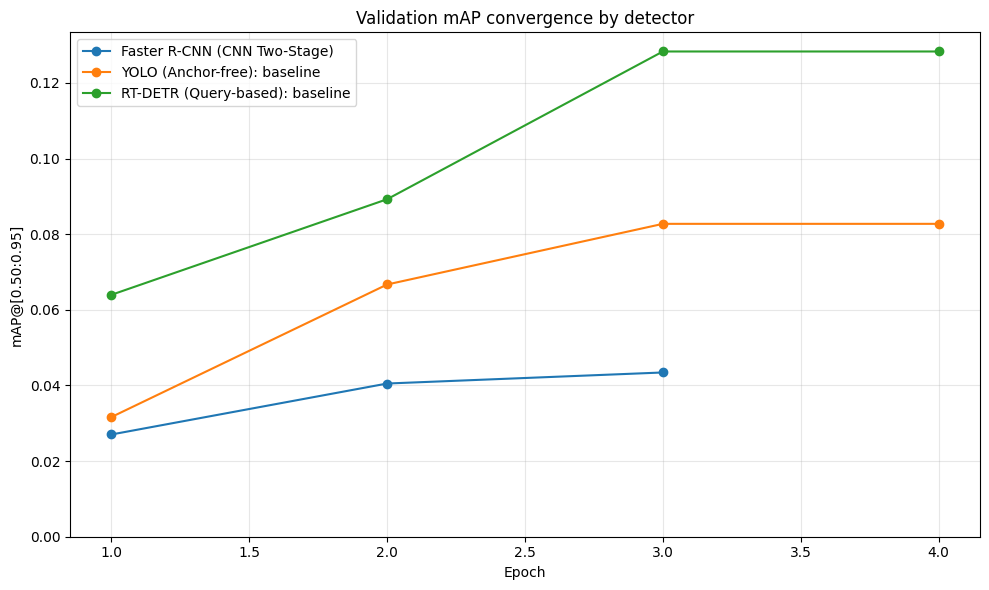

Convergence comparison saved to /Users/romanpempus/Desktop/AI/hw_2/outputs/rtdetr_vs_cnn_convergence.png


PosixPath('/Users/romanpempus/Desktop/AI/hw_2/outputs/rtdetr_vs_cnn_convergence.png')

In [20]:
from copy import copy

RTDETR_EXPERIMENT_CONFIGS: dict[str, dict[str, Any]] = {
    'baseline': {
        'model': 'rtdetr-l.pt',
        'imgsz': 448,
        'num_queries': 300,
    },
    'exp1_dense_queries': {
        'model': 'rtdetr-l.pt',
        'imgsz': 448,
        'num_queries': 500,
    },
    'exp2_lr_and_matching': {
        'model': 'rtdetr-l.pt',
        'imgsz': 448,
        'num_queries': 300,
        'lr0': 0.0001,
        'matching_cost_class': 2.5,
        'matching_cost_bbox': 5.0,
        'matching_cost_giou': 2.5,
    },
}


def prepare_rtdetr_dataset(
    config: dict[str, Any] = SHARED_CONFIG,
    data_root: str | Path | None = None,
    output_dir: str | Path | None = None,
) -> dict[str, Any]:
    """Export manifest-selected VisDrone frames to RT-DETR's YOLO input format."""
    destination = (
        Path(output_dir)
        if output_dir is not None
        else Path(config['save_dir']).expanduser() / 'visdrone_rtdetr'
    ).resolve()
    dataset = prepare_yolo_dataset(
        config=config,
        data_root=data_root,
        output_dir=destination,
    )
    if not dataset['train'] or not dataset['val']:
        raise ValueError('RT-DETR export requires non-empty train and validation splits')
    return dataset


def _set_rtdetr_num_queries(model: Any, num_queries: int) -> None:
    if num_queries < 1:
        raise ValueError('num_queries must be at least 1')
    decoders = [
        module for module in model.model.modules()
        if module.__class__.__name__ == 'RTDETRDecoder'
    ]
    if len(decoders) != 1:
        raise RuntimeError(f'expected one RTDETRDecoder, found {len(decoders)}')
    decoders[0].num_queries = int(num_queries)


def load_rtdetr_checkpoint(checkpoint_path: str | Path, device: torch.device) -> Any:
    """Load a saved RT-DETR checkpoint written with Ultralytics Model.save()."""
    from ultralytics import RTDETR

    checkpoint_path = Path(checkpoint_path).expanduser().resolve()
    if not checkpoint_path.is_file():
        raise FileNotFoundError(f'RT-DETR checkpoint not found: {checkpoint_path}')
    checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=False)
    saved_model = checkpoint.get('model') if isinstance(checkpoint, dict) else None
    if not isinstance(saved_model, torch.nn.Module):
        raise ValueError(f'checkpoint does not contain a serialized RT-DETR model: {checkpoint_path}')
    detector = RTDETR('rtdetr-l.yaml')
    detector.model = saved_model.to(device)
    detector.ckpt = checkpoint
    return detector


def evaluate_rtdetr_checkpoint(
    checkpoint: Any,
    val_loader: DataLoader[tuple[Tensor, dict[str, Tensor]]],
    image_size: int,
    device: torch.device,
    max_detections: int,
) -> dict[str, float]:
    detector = (
        load_rtdetr_checkpoint(checkpoint, device)
        if isinstance(checkpoint, (str, Path))
        else checkpoint
    )
    return evaluate_yolo_checkpoint(
        detector,
        val_loader,
        image_size,
        device,
        max_detections,
    )


@tee_training_run('rtdetr_training.txt')
def run_rtdetr_experiment(
    exp_name: str,
    exp_cfg: dict[str, Any],
    config: dict[str, Any] = SHARED_CONFIG,
) -> dict[str, Any]:
    import logging
    import warnings
    from ultralytics import RTDETR

    if exp_name not in RTDETR_EXPERIMENT_CONFIGS:
        raise ValueError(
            f'unknown RT-DETR experiment {exp_name!r}; expected one of '
            f'{", ".join(RTDETR_EXPERIMENT_CONFIGS)}'
        )
    experiment = {**RTDETR_EXPERIMENT_CONFIGS[exp_name], **exp_cfg}
    seed = int(config['seed'])
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    device = choose_device('auto')
    dataset = prepare_rtdetr_dataset(config)
    _, val_loader = _retinanet_data_loaders(config, device, sample_size=None)
    epochs = int(config['epochs'])
    if epochs < 1:
        raise ValueError("SHARED_CONFIG['epochs'] must be at least 1")
    requested_batch = int(config['batch_size'])
    if requested_batch < 1:
        raise ValueError("SHARED_CONFIG['batch_size'] must be at least 1")
    batch_size = requested_batch
    image_size = int(config['image_size'])
    project_dir = Path(config['save_dir']).expanduser().resolve() / 'ultralytics'
    project_dir.mkdir(parents=True, exist_ok=True)
    model = RTDETR(str(experiment.get('model', 'rtdetr-l.pt')))
    _set_rtdetr_num_queries(model, int(experiment.get('num_queries', 300)))
    checkpoint_path = Path(config['save_dir']).expanduser().resolve() / f'rtdetr_{exp_name}_best.pth'
    checkpoint_path.parent.mkdir(parents=True, exist_ok=True)
    epoch_map_history: list[float] = []
    best_map = float('-inf')
    best_metrics: dict[str, float] = {}
    best_epoch = 0

    def configure_matching_costs(trainer) -> None:
        cost_values = {
            'class': experiment.get('matching_cost_class'),
            'bbox': experiment.get('matching_cost_bbox'),
            'giou': experiment.get('matching_cost_giou'),
        }
        if any(value is not None for value in cost_values.values()):
            from ultralytics.models.utils.loss import RTDETRDetectionLoss
            default_costs = {'class': 2.0, 'bbox': 5.0, 'giou': 2.0}
            costs = {
                name: float(value) if value is not None else default_costs[name]
                for name, value in cost_values.items()
            }
            trainer.model.criterion = RTDETRDetectionLoss(nc=trainer.model.nc, use_vfl=True)
            trainer.model.criterion.matcher.cost_gain = costs
            print(f'RT-DETR Hungarian matching costs: {costs}')

    def log_epoch_metrics(trainer) -> None:
        nonlocal best_map, best_metrics, best_epoch
        current_model = copy(model)
        current_model.model = trainer.ema.ema
        epoch_metrics, _ = evaluate(
            UltralyticsEvaluationAdapter(
                current_model, image_size, int(config['max_detections']), device
            ),
            val_loader,
            device,
            image_size,
        )
        epoch_map = float(epoch_metrics['map'])
        epoch_map_history.append(epoch_map)
        raw_loss = trainer.tloss
        if isinstance(raw_loss, dict):
            loss_components = tuple(raw_loss.values())
        elif isinstance(raw_loss, (list, tuple)):
            loss_components = tuple(raw_loss)
        else:
            loss_components = (raw_loss,)
        loss_tensors = [
            torch.as_tensor(value).detach().float().mean().cpu()
            for value in loss_components
        ]
        epoch_loss = float(torch.stack(loss_tensors).mean().item()) if loss_tensors else 0.0
        learning_rate = float(trainer.optimizer.param_groups[0]['lr'])
        epoch_duration = float(trainer.epoch_time)
        saved_message = ''
        if epoch_map > best_map:
            best_map = epoch_map
            best_metrics = dict(epoch_metrics)
            best_epoch = int(trainer.epoch) + 1
            current_model.save(str(checkpoint_path))
            saved_message = f' | saved best checkpoint: {checkpoint_path}'
        print(
            f"[{exp_name}] Epoch {int(trainer.epoch) + 1}/{epochs} | loss={epoch_loss:.4f} | "
            f"lr={learning_rate:.6g} | mAP@[0.50:0.95]={epoch_map:.4f} | "
            f"AP50={epoch_metrics['map_50']:.4f} | AP75={epoch_metrics['map_75']:.4f} | "
            f"AP_small={epoch_metrics['map_small']:.4f} | "
            f"inference_ms={epoch_metrics['inference_ms']:.2f} | "
            f"fps={epoch_metrics['fps']:.2f} | epoch_time={epoch_duration:.1f}s"
            f"{saved_message}"
        )

    model.add_callback('on_train_start', configure_matching_costs)
    model.add_callback('on_fit_epoch_end', log_epoch_metrics)
    train_options: dict[str, Any] = {
        'data': str(dataset['data_yaml']),
        'epochs': epochs,
        'imgsz': image_size,
        'batch': batch_size,
        'seed': seed,
        'deterministic': True,
        'pretrained': True,
        'device': _yolo_device_for_training(device),
        'workers': 2,
        'max_det': int(config['max_detections']),
        'project': str(project_dir),
        'name': f'rtdetr_{exp_name}',
        'exist_ok': False,
        'patience': epochs + 1,
        'plots': False,
        'verbose': False,
    }
    if 'lr0' in experiment:
        train_options['lr0'] = float(experiment['lr0'])
    ultralytics_logger = logging.getLogger('ultralytics')
    with warnings.catch_warnings():
        warnings.filterwarnings('ignore')
        ultralytics_logger.setLevel(logging.WARNING)
        try:
            model.train(**train_options)
        finally:
            ultralytics_logger.setLevel(logging.INFO)
    if not epoch_map_history:
        raise RuntimeError('RT-DETR training finished without validation epoch metrics')
    if not checkpoint_path.is_file():
        raise FileNotFoundError(f'RT-DETR did not save its best checkpoint: {checkpoint_path}')
    download_checkpoint(checkpoint_path)
    summary = {
        'model_family': 'RT-DETR (Query-based)',
        'experiment': exp_name,
        'best_map': best_map,
        'ap50': best_metrics['map_50'],
        'ap_small': best_metrics['map_small'],
        'ap_medium': best_metrics['map_medium'],
        'ap_large': best_metrics['map_large'],
        'inference_ms': best_metrics['inference_ms'],
        'fps': best_metrics['fps'],
        'checkpoint_path': str(checkpoint_path),
        'epoch_map_history': epoch_map_history,
    }
    markdown = (
        f"\n| Model | Experiment | Best mAP@[0.50:0.95] | AP50 | AP_small | "
        f"AP_medium | AP_large | inference_ms | fps |\n"
        f"| --- | --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |\n"
        f"| RT-DETR (Query-based) | {exp_name} | {best_map:.4f} | "
        f"{best_metrics['map_50']:.4f} | {best_metrics['map_small']:.4f} | "
        f"{best_metrics['map_medium']:.4f} | {best_metrics['map_large']:.4f} | "
        f"{best_metrics['inference_ms']:.2f} | {best_metrics['fps']:.2f} |\n"
    )
    summary_path = Path(LOCAL_OUTPUT_DIR) / 'evaluation_summary.md'
    summary_path.parent.mkdir(parents=True, exist_ok=True)
    with summary_path.open('a', encoding='utf-8') as summary_file:
        summary_file.write(markdown)
    append_output_log(
        Path(LOCAL_OUTPUT_DIR) / 'evaluation_summary.txt',
        f"RT-DETR {exp_name} | best_epoch={best_epoch} | "
        f"mAP@[0.50:0.95]={best_map:.4f} | AP50={best_metrics['map_50']:.4f} | "
        f"AP_small={best_metrics['map_small']:.4f} | "
        f"AP_medium={best_metrics['map_medium']:.4f} | "
        f"AP_large={best_metrics['map_large']:.4f} | "
        f"inference_ms={best_metrics['inference_ms']:.2f} | fps={best_metrics['fps']:.2f}"
    )
    return summary


def plot_training_convergence_comparison(
    histories: dict[str, list[float]] | None = None,
) -> Path:
    import matplotlib.pyplot as plt

    if histories is None:
        histories = {}
        faster_history = globals().get('FASTER_RCNN_MAP_HISTORY', [])
        if faster_history:
            histories['Faster R-CNN (CNN Two-Stage)'] = list(faster_history)
        for variable, family in (
            ('retinanet_results', 'RetinaNet (CNN One-Stage)'),
            ('yolo_results', 'YOLO (Anchor-free)'),
            ('rtdetr_results', 'RT-DETR (Query-based)'),
        ):
            for result in globals().get(variable, []):
                values = result.get('epoch_map_history')
                if values:
                    histories[f"{family}: {result.get('experiment', 'run')}"] = list(values)
    histories = {name: values for name, values in histories.items() if values}
    if not histories:
        raise ValueError('no per-epoch mAP histories are available to plot')
    figure, axis = plt.subplots(figsize=(10, 6))
    for name, values in histories.items():
        axis.plot(range(1, len(values) + 1), values, marker='o', label=name)
    axis.set(title='Validation mAP convergence by detector', xlabel='Epoch', ylabel='mAP@[0.50:0.95]')
    axis.set_ylim(bottom=0)
    axis.grid(True, alpha=0.3)
    axis.legend()
    figure.tight_layout()
    output_path = Path(LOCAL_OUTPUT_DIR) / 'rtdetr_vs_cnn_convergence.png'
    output_path.parent.mkdir(parents=True, exist_ok=True)
    figure.savefig(output_path, bbox_inches='tight', dpi=300)
    try:
        from IPython.display import display
        display(figure)
    except ImportError:
        plt.show()
    plt.close(figure)
    print(f'Convergence comparison saved to {output_path}')
    return output_path


RUN_RTDETR_EXPERIMENTS = ['baseline']
rtdetr_results = [
    run_rtdetr_experiment(name, RTDETR_EXPERIMENT_CONFIGS[name])
    for name in RUN_RTDETR_EXPERIMENTS
]
rtdetr_results_df = pd.DataFrame(rtdetr_results)
try:
    from IPython.display import display
    display(rtdetr_results_df)
except ImportError:
    print(rtdetr_results_df.to_string(index=False))
plot_training_convergence_comparison()

In [4]:
from pathlib import Path

ckpt_dir = Path("/content/outputs/checkpoints")
ckpt_dir.mkdir(parents=True, exist_ok=True)
print("Checkpoints found:", [f.name for f in ckpt_dir.glob("*")])

Checkpoints found: []


In [5]:
from pathlib import Path

colab_eda_dir = Path("/content/outputs/eda")
colab_eda_dir.mkdir(parents=True, exist_ok=True)
print(f"Created directory: {colab_eda_dir}")

Created directory: /content/outputs/eda


In [6]:
import shutil
from pathlib import Path

# Paths
source_manifest = Path('/Users/romanpempus/Desktop/AI/hw_2/outputs/eda/sequence_split.csv')
target_dir = Path('/content/outputs/eda')

# Create directory and copy file
target_dir.mkdir(parents=True, exist_ok=True)
if source_manifest.is_file():
    shutil.copy(source_manifest, target_dir / 'sequence_split.csv')
    print('✅ Successfully copied sequence_split.csv to /content/outputs/eda/')
else:
    print(f'❌ Source file not found at {source_manifest}')

❌ Source file not found at /Users/romanpempus/Desktop/AI/hw_2/outputs/eda/sequence_split.csv


In [10]:
from pathlib import Path

# Adjust filenames according to Step 1 output:
EVAL_CHECKPOINTS = {
    "Faster R-CNN Baseline": "/content/outputs/checkpoints/faster_rcnn_resnet50_fpn_v2_best.pth",
    "RetinaNet Baseline": "/content/outputs/checkpoints/retinanet_baseline_best.pth", # or onestage_retinanet_baseline_best.pth
    "YOLOv8n Baseline": "/content/outputs/checkpoints/yolo_baseline_best.pth",
    "RT-DETR Baseline": "/content/outputs/checkpoints/rtdetr_baseline_best.pth",
}

# Verify all paths exist before starting loop
for name, path in EVAL_CHECKPOINTS.items():
    p = Path(path)
    print(f"{'✅' if p.is_file() else '❌'} {name}: {p}")

❌ Faster R-CNN Baseline: /content/outputs/checkpoints/faster_rcnn_resnet50_fpn_v2_best.pth
❌ RetinaNet Baseline: /content/outputs/checkpoints/retinanet_baseline_best.pth
❌ YOLOv8n Baseline: /content/outputs/checkpoints/yolo_baseline_best.pth
❌ RT-DETR Baseline: /content/outputs/checkpoints/rtdetr_baseline_best.pth


In [8]:
from pathlib import Path

EVAL_CHECKPOINTS = {
    "Faster R-CNN Baseline": "./outputs/checkpoints/faster_rcnn_resnet50_fpn_v2_best.pth",
    "RetinaNet Baseline": "./outputs/checkpoints/onestage_retinanet_baseline_best.pth",
    "YOLOv8n Baseline": "./outputs/checkpoints/yolo_baseline_best.pth",
    "RT-DETR Baseline": "./outputs/checkpoints/rtdetr_baseline_best.pth",
}

print("Updated EVAL_CHECKPOINTS dictionary for local path execution.")

Updated EVAL_CHECKPOINTS dictionary for local path execution.


In [13]:
!pip install torch torchvision torchaudio
!pip install ultralytics torchmetrics pandas numpy matplotlib pillow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 12.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 16.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [ultralytics] [ultralytics]]


# Unified full-validation benchmark for every discovered trained checkpoint


In [ ]:
# Unified full-validation benchmark for every discovered trained checkpoint.
import json
import logging
import math
import time
from itertools import chain
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
from torchmetrics.detection.mean_ap import MeanAveragePrecision

EVAL_IMAGE_SIZE = int(SHARED_CONFIG['image_size'])
EVAL_MAX_DETECTIONS = int(SHARED_CONFIG['max_detections'])
EVAL_CLASS_NAMES = ('person', 'bicycle', 'car', 'van', 'truck', 'tricycle', 'bus', 'motor')
EVAL_DRIVE_ROOT = Path('/content/drive/MyDrive/hw_2')
EVAL_MANIFEST = EVAL_DRIVE_ROOT / 'outputs' / 'eda' / 'sequence_split.csv'
EVAL_DRIVE_CHECKPOINT_DIR = EVAL_DRIVE_ROOT / 'outputs' / 'checkpoints'
EVAL_OUTPUT_DIR = Path(globals().get('LOCAL_OUTPUT_DIR', Path('/content/outputs'))).expanduser()
FAILURE_OUTPUT_DIR = Path(globals().get('FAILURE_OUTPUT_DIR', EVAL_OUTPUT_DIR / 'failures')).expanduser()
EVAL_CHECKPOINT_DIR = EVAL_DRIVE_CHECKPOINT_DIR
EVAL_RESULTS_JSON = EVAL_OUTPUT_DIR / 'eval_results.json'
EVAL_RESULTS_CSV = EVAL_OUTPUT_DIR / 'eval_results.csv'
EVAL_LOG_PATH = EVAL_OUTPUT_DIR / 'logs' / 'model_evaluation.log'
EVAL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FAILURE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
EVAL_LOG_PATH.parent.mkdir(parents=True, exist_ok=True)
_eval_logger = logging.getLogger('visdrone_model_benchmark')
_eval_logger.setLevel(logging.INFO)
_eval_logger.handlers.clear()
_eval_handler = logging.FileHandler(EVAL_LOG_PATH, mode='a', encoding='utf-8')
_eval_handler.setFormatter(logging.Formatter('%(asctime)s | %(levelname)s | %(message)s'))
_eval_logger.addHandler(_eval_handler)

if Path('/content').is_dir() and not Path('/content/drive/MyDrive').is_dir():
    try:
        from google.colab import drive
    except ImportError:
        pass
    else:
        drive.mount('/content/drive')

EVAL_GLOBAL_CHECKPOINT_DIR = Path(globals().get('CHECKPOINT_OUTPUT_DIR') or EVAL_OUTPUT_DIR / 'checkpoints')
EVAL_LOCAL_CHECKPOINT_DIR = EVAL_OUTPUT_DIR / 'checkpoints'
EVAL_CHECKPOINT_DIR_CANDIDATES = (
    EVAL_DRIVE_ROOT,
    EVAL_DRIVE_CHECKPOINT_DIR,
    EVAL_DRIVE_ROOT / 'checkpoints',
    EVAL_GLOBAL_CHECKPOINT_DIR,
    EVAL_LOCAL_CHECKPOINT_DIR,
)
EVAL_CHECKPOINT_SEARCH_ROOTS = tuple(dict.fromkeys(
    candidate.expanduser().resolve()
    for candidate in (EVAL_DRIVE_ROOT, EVAL_GLOBAL_CHECKPOINT_DIR, EVAL_LOCAL_CHECKPOINT_DIR)
    if candidate.expanduser().is_dir()
))
EVAL_CHECKPOINT_DIR = EVAL_CHECKPOINT_SEARCH_ROOTS[0] if EVAL_CHECKPOINT_SEARCH_ROOTS else EVAL_DRIVE_ROOT.expanduser().resolve()

if not torch.cuda.is_available():
    raise RuntimeError('This benchmark requires a CUDA GPU for comparable latency/FPS. In Colab, select Runtime > Change runtime type > T4 GPU, then rerun this cell.')
EVAL_DEVICE = torch.device('cuda')
EVAL_DRIVE_MANIFEST_FILES = tuple(sorted(EVAL_DRIVE_ROOT.rglob('sequence_split.csv'))) if EVAL_DRIVE_ROOT.is_dir() else ()
EVAL_MANIFEST_CANDIDATES = tuple(dict.fromkeys((
    EVAL_MANIFEST,
    *EVAL_DRIVE_MANIFEST_FILES,
    Path('/content/outputs/eda/sequence_split.csv'),
    EVAL_OUTPUT_DIR / 'eda' / 'sequence_split.csv',
    Path('./outputs/eda/sequence_split.csv'),
    Path((globals().get('SHARED_CONFIG') or {}).get('manifest') or EVAL_MANIFEST),
)))
EVAL_MANIFEST = next((candidate.expanduser().resolve() for candidate in EVAL_MANIFEST_CANDIDATES if candidate.expanduser().is_file()), None)
if EVAL_MANIFEST is None:
    checked_manifests = ', '.join(str(candidate.expanduser()) for candidate in EVAL_MANIFEST_CANDIDATES)
    raise FileNotFoundError(f'Could not find the validation manifest. Checked: {checked_manifests}. Confirm Google Drive is mounted and sequence_split.csv exists.')
EVAL_DATA_ROOT = Path('/content/data')
if not EVAL_DATA_ROOT.is_dir():
    EVAL_DATA_ROOT = default_data_root()
EVAL_DATA_ROOT = EVAL_DATA_ROOT.expanduser().resolve()
EVAL_RECORDS, EVAL_DATA_SOURCE = load_records(EVAL_MANIFEST, EVAL_DATA_ROOT)




# EVAL_VAL_RECORDS = [record for record in EVAL_RECORDS if record.assigned_split == 'val']
# Subsample every 10th frame to keep ~529 frames for fast benchmarking
EVAL_VAL_RECORDS = [record for record in EVAL_RECORDS if record.assigned_split == 'val'][::10]






EVAL_VAL_CLIPS = sorted({record.clip_id for record in EVAL_VAL_RECORDS})
if len(EVAL_VAL_CLIPS) != 13:
    raise ValueError(f'Expected the 13 sequence-level validation clips from the manifest, found {len(EVAL_VAL_CLIPS)}: {EVAL_VAL_CLIPS}')
if not EVAL_VAL_RECORDS:
    raise ValueError(f'No validation frames were assigned in {EVAL_MANIFEST}')
EVAL_DATASET = VisDroneDetectionDataset(EVAL_VAL_RECORDS, EVAL_DATA_ROOT, 'val', image_size=EVAL_IMAGE_SIZE, mask_ignore_pixels=True)
EVAL_LOADER = DataLoader(EVAL_DATASET, batch_size=1, shuffle=False, num_workers=2, pin_memory=True, collate_fn=detection_collate)
print(f'Validation manifest: {EVAL_MANIFEST} | source={EVAL_DATA_SOURCE}')
print(f'Validation clips: {len(EVAL_VAL_CLIPS)} | frames: {len(EVAL_DATASET)} | device: {EVAL_DEVICE} | size: {EVAL_IMAGE_SIZE} | max detections: {EVAL_MAX_DETECTIONS}')
_eval_logger.info('manifest=%s source=%s clips=%s frames=%d device=%s image_size=%d max_detections=%d', EVAL_MANIFEST, EVAL_DATA_SOURCE, EVAL_VAL_CLIPS, len(EVAL_DATASET), EVAL_DEVICE, EVAL_IMAGE_SIZE, EVAL_MAX_DETECTIONS)

# Optional explicit mapping can be supplied before running this cell.
EVAL_CHECKPOINTS: dict[str, str | Path] = dict(globals().get('EVAL_CHECKPOINTS', globals().get('MODEL_CHECKPOINTS', {})))
EVAL_CHECKPOINT_FILES = sorted({
    _path.resolve()
    for _root in EVAL_CHECKPOINT_SEARCH_ROOTS
    for _path in chain(_root.rglob('*.pth'), _root.rglob('*.pt'))
    if _path.is_file()
})
for _path in EVAL_CHECKPOINT_FILES:
    _text, _name = str(_path).lower(), _path.name.lower()
    if _path.suffix.lower() == '.pth' and any(token in _name for token in ('faster_rcnn', 'fasterrcnn', 'retinanet', 'rtdetr', 'yolo')):
        EVAL_CHECKPOINTS.setdefault(_path.stem, _path)
    elif _path.suffix.lower() == '.pt':
        model_name = _path.parent.parent.name if _name == 'best.pt' and 'ultralytics' in _text else _path.stem
        EVAL_CHECKPOINTS.setdefault(model_name, _path)
if not EVAL_CHECKPOINTS:
    checked_checkpoint_dirs = ', '.join(str(candidate.expanduser()) for candidate in EVAL_CHECKPOINT_DIR_CANDIDATES)
    raise FileNotFoundError(f'No trained checkpoints found. Checked: {checked_checkpoint_dirs}. Confirm Google Drive is mounted, verify the checkpoints folder, or set CHECKPOINT_OUTPUT_DIR/EVAL_CHECKPOINTS explicitly.')

def _eval_family(name: str, path: Path) -> str:
    identity = f'{name} {path}'.lower()
    if 'rtdetr' in identity or 'rt-detr' in identity:
        return 'rtdetr'
    if 'retina' in identity:
        return 'retinanet'
    if 'faster' in identity:
        return 'faster_rcnn'
    if 'yolo' in identity or path.suffix.lower() == '.pt':
        return 'yolo'
    raise ValueError(f'Cannot infer detector family for {path}; include faster_rcnn, retinanet, rtdetr, or yolo in its name.')

def _eval_target(target: dict[str, torch.Tensor]) -> dict[str, torch.Tensor]:
    boxes = target['original_boxes'].detach().cpu().to(torch.float32)
    labels = target['original_labels'].detach().cpu().to(torch.int64)
    crowd = target['original_iscrowd'].detach().cpu().to(torch.int64)
    regular = crowd == 0
    out_boxes, out_labels = boxes[regular], labels[regular]
    ignored = boxes[crowd == 1]
    if len(ignored):
        out_boxes = torch.cat((out_boxes, ignored.repeat(len(EVAL_CLASS_NAMES), 1)))
        out_labels = torch.cat((out_labels, torch.arange(1, 9).repeat_interleave(len(ignored))))
        out_crowd = torch.cat((torch.zeros(int(regular.sum()), dtype=torch.int64), torch.ones(8 * len(ignored), dtype=torch.int64)))
    else:
        out_crowd = torch.zeros(len(out_boxes), dtype=torch.int64)
    area = (out_boxes[:, 2] - out_boxes[:, 0]).clamp(min=0) * (out_boxes[:, 3] - out_boxes[:, 1]).clamp(min=0)
    return {'boxes': out_boxes, 'labels': out_labels, 'iscrowd': out_crowd, 'area': area}

def _eval_load_model(name: str, path: Path) -> tuple[str, Any]:
    family = _eval_family(name, path)
    if path.suffix.lower() == '.pth':
        checkpoint = torch.load(path, map_location='cpu', weights_only=False)
        if family == 'rtdetr':
            return family, load_rtdetr_checkpoint(path, EVAL_DEVICE)
        if family == 'yolo':
            from ultralytics import YOLO
            saved_model = checkpoint.get('ema')
            if not isinstance(saved_model, torch.nn.Module):
                saved_model = checkpoint.get('model')
            if not isinstance(saved_model, torch.nn.Module):
                raise ValueError(f'{path} does not contain a serialized Ultralytics model')
            detector = YOLO('yolov8n.yaml')
            detector.model = saved_model.to(EVAL_DEVICE)
            detector.ckpt = checkpoint
            return family, detector
        if not isinstance(checkpoint, dict) or not isinstance(checkpoint.get('model_state_dict'), dict):
            raise ValueError(f'{path} must contain a model_state_dict')
        exp_cfg = checkpoint.get('exp_cfg', {})
        if family == 'retinanet':
            model = build_retinanet_model(device=EVAL_DEVICE, image_size=EVAL_IMAGE_SIZE, max_detections=EVAL_MAX_DETECTIONS, anchor_sizes=exp_cfg.get('anchor_sizes'), prior_prob=float(exp_cfg.get('prior_prob', 0.01)), focal_alpha=float(exp_cfg.get('focal_alpha', 0.25)), focal_gamma=float(exp_cfg.get('focal_gamma', 2.0)))
        else:
            model = build_model(EVAL_DEVICE, EVAL_IMAGE_SIZE, 1000, 512, EVAL_MAX_DETECTIONS)
        model.load_state_dict(checkpoint['model_state_dict'])
        model.eval()
        return family, model
    if family == 'rtdetr':
        from ultralytics import RTDETR
        return family, RTDETR(str(path))
    from ultralytics import YOLO
    return family, YOLO(str(path))

def _eval_predict(family: str, model: Any, image: torch.Tensor) -> dict[str, torch.Tensor]:
    if family in {'faster_rcnn', 'retinanet'}:
        output = model([image.to(EVAL_DEVICE)])[0]
        boxes = output['boxes'].detach().cpu().to(torch.float32)
        scores = output['scores'].detach().cpu().to(torch.float32)
        labels = output['labels'].detach().cpu().to(torch.int64)
    else:
        mean = torch.tensor(IMAGE_MEAN, dtype=image.dtype).view(3, 1, 1)
        std = torch.tensor(IMAGE_STD, dtype=image.dtype).view(3, 1, 1)
        rgb = (image.detach().cpu() * std + mean).clamp(0, 1)
        rgb = (rgb.permute(1, 2, 0).numpy() * 255).round().astype(np.uint8)
        bgr = np.ascontiguousarray(rgb[:, :, ::-1])
        result = model.predict(source=bgr, imgsz=EVAL_IMAGE_SIZE, conf=0.001, max_det=EVAL_MAX_DETECTIONS, device=EVAL_DEVICE.index or 0, verbose=False)[0]
        if result.boxes is None or len(result.boxes) == 0:
            boxes, scores, labels = torch.empty((0, 4)), torch.empty(0), torch.empty(0, dtype=torch.int64)
        else:
            boxes = result.boxes.xyxy.detach().cpu().to(torch.float32)
            scores = result.boxes.conf.detach().cpu().to(torch.float32)
            labels = result.boxes.cls.detach().cpu().to(torch.int64) + 1
    if len(scores) > EVAL_MAX_DETECTIONS:
        keep = torch.argsort(scores, descending=True)[:EVAL_MAX_DETECTIONS]
        boxes, scores, labels = boxes[keep], scores[keep], labels[keep]
    if len(labels) and ((labels < 1).any() or (labels > 8).any()):
        raise ValueError(f'Predicted labels must map to VisDrone IDs 1..8; found {labels.unique().tolist()}')
    return {'boxes': boxes, 'scores': scores, 'labels': labels}

def _eval_save(rows: list[dict[str, Any]]) -> None:
    pd.DataFrame(rows).to_csv(EVAL_RESULTS_CSV, index=False)
    json_rows = [{key: (None if isinstance(value, float) and not math.isfinite(value) else value) for key, value in row.items()} for row in rows]
    payload = {'manifest': str(EVAL_MANIFEST), 'data_root': str(EVAL_DATA_ROOT), 'validation_source': EVAL_DATA_SOURCE, 'validation_clip_count': len(EVAL_VAL_CLIPS), 'validation_clips': EVAL_VAL_CLIPS, 'validation_image_count': len(EVAL_DATASET), 'image_size': EVAL_IMAGE_SIZE, 'batch_size': 1, 'max_detections': EVAL_MAX_DETECTIONS, 'mask_ignore_pixels': True, 'device': str(EVAL_DEVICE), 'metrics': json_rows}
    EVAL_RESULTS_JSON.write_text(json.dumps(payload, indent=2, allow_nan=False), encoding='utf-8')

EVAL_FAILURE_SCORE_THRESHOLD = 0.25
EVAL_FAILURE_IOU_THRESHOLD = 0.50
EVAL_FAILURE_PREDICTION_LIMIT = 40

def _eval_failure_analysis(prediction: dict[str, torch.Tensor], target: dict[str, torch.Tensor]) -> dict[str, Any]:
    gt_keep = target['original_iscrowd'].detach().cpu() == 0
    gt_boxes = target['original_boxes'].detach().cpu()[gt_keep]
    gt_labels = target['original_labels'].detach().cpu()[gt_keep]
    boxes = prediction['boxes'].detach().cpu()
    scores = prediction['scores'].detach().cpu()
    labels = prediction['labels'].detach().cpu()
    considered = torch.where(scores >= EVAL_FAILURE_SCORE_THRESHOLD)[0]
    matched = torch.zeros(len(boxes), dtype=torch.bool)
    matched_gt = torch.zeros(len(gt_boxes), dtype=torch.bool)
    false_positives = 0
    mislocalized = 0

    for prediction_index in considered[torch.argsort(scores[considered], descending=True)].tolist():
        same_class = gt_labels == labels[prediction_index]
        eligible = same_class & ~matched_gt
        if eligible.any():
            candidate_indices = torch.where(eligible)[0]
            candidate_boxes = gt_boxes[candidate_indices]
            box = boxes[prediction_index]
            top_left = torch.maximum(candidate_boxes[:, :2], box[:2])
            bottom_right = torch.minimum(candidate_boxes[:, 2:], box[2:])
            intersection = (bottom_right - top_left).clamp(min=0).prod(dim=1)
            candidate_area = (candidate_boxes[:, 2:] - candidate_boxes[:, :2]).clamp(min=0).prod(dim=1)
            box_area = (box[2:] - box[:2]).clamp(min=0).prod()
            ious = intersection / (candidate_area + box_area - intersection).clamp(min=1e-12)
            best_iou, best_local_index = ious.max(dim=0)
            if float(best_iou) >= EVAL_FAILURE_IOU_THRESHOLD:
                matched_gt[candidate_indices[best_local_index]] = True
                matched[prediction_index] = True
                continue
            if float(best_iou) >= 0.10:
                mislocalized += 1
        false_positives += 1

    false_negatives = int((~matched_gt).sum().item())
    reasons = []
    if false_positives:
        reasons.append(f'{false_positives} false positive(s)')
    if false_negatives:
        reasons.append(f'{false_negatives} missed target(s)')
    if mislocalized:
        reasons.append(f'{mislocalized} poorly localized prediction(s)')
    return {
        'false_positives': false_positives,
        'false_negatives': false_negatives,
        'mislocalized': mislocalized,
        'failure_score': false_positives + false_negatives,
        'reasons': reasons or ['no errors at the selected score/IoU thresholds'],
        'matched_predictions': matched,
        'considered_predictions': considered,
    }

def _eval_save_failure_case(model_name: str, case_number: int, case: dict[str, Any]) -> Path:
    from PIL import Image
    from matplotlib.patches import Patch, Rectangle

    record = case['record']
    with Image.open(record.image_path) as source_image:
        image = source_image.convert('RGB')
    target = case['target']
    prediction = case['prediction']
    figure, axis = plt.subplots(figsize=(14, 9))
    axis.imshow(image)
    gt_keep = target['original_iscrowd'] == 0
    for box, label in zip(target['original_boxes'][gt_keep], target['original_labels'][gt_keep]):
        x1, y1, x2, y2 = map(float, box.tolist())
        axis.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor='#22c55e', linewidth=1.2))

    scores = prediction['scores']
    matched = case['matched_predictions']
    considered = case['considered_predictions'].tolist()
    false_positive_indices = sorted(
        (index for index in considered if not bool(matched[index])),
        key=lambda index: float(scores[index]), reverse=True,
    )
    selected = false_positive_indices[:EVAL_FAILURE_PREDICTION_LIMIT]
    for index in torch.argsort(scores, descending=True).tolist():
        if index in considered and index not in selected and len(selected) < EVAL_FAILURE_PREDICTION_LIMIT:
            selected.append(index)
    for index in selected:
        box = prediction['boxes'][index]
        label = int(prediction['labels'][index])
        score = float(scores[index])
        x1, y1, x2, y2 = map(float, box.tolist())
        color = '#2563eb' if bool(matched[index]) else '#ef4444'
        axis.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=color, linewidth=1.4))
        axis.text(x1, max(0, y1 - 2), f'{EVAL_CLASS_NAMES[label - 1]} {score:.2f}', color='white', fontsize=7,
                  bbox={'facecolor': color, 'edgecolor': 'none', 'alpha': 0.85, 'pad': 1.5})

    reasons = ', '.join(case['reasons'])
    axis.set_title(f'{model_name} | failure case {case_number} | {reasons}')
    axis.axis('off')
    axis.legend(handles=[Patch(edgecolor='#22c55e', facecolor='none', label='Ground truth'),
                         Patch(edgecolor='#2563eb', facecolor='none', label='Matched prediction'),
                         Patch(edgecolor='#ef4444', facecolor='none', label='Unmatched prediction')],
                loc='upper right')
    figure.tight_layout()
    safe_model_name = ''.join(character if character.isalnum() or character in '._-' else '_' for character in model_name).strip('._')
    output_path = FAILURE_OUTPUT_DIR / f'failure_{safe_model_name or "model"}_case_{case_number}.png'
    figure.savefig(output_path, bbox_inches='tight', dpi=180)
    plt.show()
    plt.close(figure)
    return output_path

EVAL_ROWS: list[dict[str, Any]] = []
for model_name, checkpoint_value in EVAL_CHECKPOINTS.items():
    checkpoint_path = Path(checkpoint_value).expanduser().resolve()
    if not checkpoint_path.is_file():
        raise FileNotFoundError(f'{model_name}: checkpoint not found: {checkpoint_path}')
    family, model = _eval_load_model(model_name, checkpoint_path)
    # COCO AP uses the standard maxDets=[1, 10, 100]; inference above still permits 500 boxes/frame.
    metric = MeanAveragePrecision(box_format='xyxy', iou_type='bbox', iou_thresholds=[0.50 + index * 0.05 for index in range(10)], rec_thresholds=[index / 100 for index in range(101)], max_detection_thresholds=[1, 10, 100], class_metrics=True)
    inference_seconds = 0.0
    failure_candidates: list[dict[str, Any]] = []
    with torch.inference_mode():
        for frame_index, (images, targets) in enumerate(EVAL_LOADER):
            image, target = images[0], targets[0]
            torch.cuda.synchronize(EVAL_DEVICE)
            started = time.perf_counter()
            prediction = _eval_predict(family, model, image)
            torch.cuda.synchronize(EVAL_DEVICE)
            inference_seconds += time.perf_counter() - started
            original_height, original_width = map(int, target['original_size'].tolist())
            scale = torch.tensor([original_width / EVAL_IMAGE_SIZE, original_height / EVAL_IMAGE_SIZE] * 2, dtype=torch.float32)
            prediction['boxes'] *= scale
            metric.update([prediction], [_eval_target(target)])
            failure = _eval_failure_analysis(prediction, target)
            case = {
                **failure,
                'record': EVAL_DATASET.records[int(target['image_id'])],
                'target': {key: value.detach().cpu().clone() for key, value in target.items()},
                'prediction': {key: value.detach().cpu().clone() for key, value in prediction.items()},
                'frame_index': frame_index,
            }
            failure_candidates.append(case)
            failure_candidates.sort(
                key=lambda item: (item['failure_score'], item['false_positives'], item['false_negatives'],
                                  len(item['target']['original_boxes']), len(item['considered_predictions']), -item['frame_index']),
                reverse=True,
            )
            del failure_candidates[3:]
    if len(failure_candidates) < 3:
        _eval_logger.warning('model=%s had only %d validation frame(s); fewer than 3 frames were available for failure visualization', model_name, len(failure_candidates))
    for case_number, case in enumerate(failure_candidates, start=1):
        failure_plot_path = _eval_save_failure_case(model_name, case_number, case)
        _eval_logger.info(
            'failure_case model=%s case=%d image=%s false_positives=%d false_negatives=%d mislocalized=%d reasons=%s plot=%s',
            model_name, case_number, case['record'].image_path, case['false_positives'], case['false_negatives'],
            case['mislocalized'], '; '.join(case['reasons']), failure_plot_path,
        )
    computed = metric.compute()
    class_ap = {name: float('nan') for name in EVAL_CLASS_NAMES}
    for class_id, value in zip(computed['classes'].tolist(), computed['map_per_class'].tolist()):
        if 1 <= int(class_id) <= 8:
            value = float(value)
            class_ap[EVAL_CLASS_NAMES[int(class_id) - 1]] = value if math.isfinite(value) and value >= 0 else float('nan')
    mean_seconds = inference_seconds / len(EVAL_DATASET)
    row: dict[str, Any] = {'model': model_name, 'family': family, 'checkpoint': str(checkpoint_path), 'mAP@50:95': float(computed['map'].item()), 'mAP@50': float(computed['map_50'].item()), 'mAP@75': float(computed['map_75'].item()), 'inference_ms': mean_seconds * 1000, 'fps': 1 / mean_seconds if mean_seconds > 0 else float('inf'), 'images': len(EVAL_DATASET)}
    row.update({f'AP_{name}': value for name, value in class_ap.items()})
    EVAL_ROWS.append(row)
    _eval_save(EVAL_ROWS)
    _eval_logger.info('completed model=%s family=%s metrics=%s', model_name, family, row)
    print(f"{model_name} | mAP@50:95={row['mAP@50:95']:.4f} | mAP@50={row['mAP@50']:.4f} | latency={row['inference_ms']:.2f} ms | FPS={row['fps']:.2f}")
    del model, metric
    torch.cuda.empty_cache()

EVAL_RESULTS_DF = pd.DataFrame(EVAL_ROWS)
print(f'\n## VisDrone Validation Benchmark: {len(EVAL_RESULTS_DF)} models, {len(EVAL_DATASET)} frames, {len(EVAL_VAL_CLIPS)} clips')
display(EVAL_RESULTS_DF)
figure, axis = plt.subplots(figsize=(max(8, len(EVAL_ROWS) * 1.2), 5))
axis.bar(EVAL_RESULTS_DF['model'], EVAL_RESULTS_DF['mAP@50'], color='#3b82f6')
axis.set(title='VisDrone validation mAP@50 by model', ylabel='mAP@50', ylim=(0, 1))
axis.tick_params(axis='x', labelrotation=35)
axis.grid(axis='y', alpha=0.25)
figure.tight_layout()
MAP50_PLOT_PATH = EVAL_OUTPUT_DIR / 'eval_map50_comparison.png'
figure.savefig(MAP50_PLOT_PATH, bbox_inches='tight', dpi=300)
plt.show()
plt.close(figure)

class_columns = [f'AP_{name}' for name in EVAL_CLASS_NAMES]
class_matrix = EVAL_RESULTS_DF.set_index('model')[class_columns].to_numpy(dtype=float)
figure, axis = plt.subplots(figsize=(max(9, len(EVAL_ROWS) * 1.3), 6))
heatmap = axis.imshow(np.ma.masked_invalid(class_matrix), cmap='viridis', vmin=0, vmax=1, aspect='auto')
axis.set_xticks(range(8), EVAL_CLASS_NAMES, rotation=35, ha='right')
axis.set_yticks(range(len(EVAL_RESULTS_DF)), EVAL_RESULTS_DF['model'])
axis.set_title('Per-class COCO AP@[.50:.95]')
for row_index in range(class_matrix.shape[0]):
    for column_index in range(class_matrix.shape[1]):
        value = class_matrix[row_index, column_index]
        axis.text(column_index, row_index, f'{value:.2f}' if math.isfinite(value) else 'N/A', ha='center', va='center', fontsize=8)
figure.colorbar(heatmap, ax=axis, label='AP@[.50:.95]')
figure.tight_layout()
CLASS_AP_PLOT_PATH = EVAL_OUTPUT_DIR / 'eval_per_class_ap_heatmap.png'
figure.savefig(CLASS_AP_PLOT_PATH, bbox_inches='tight', dpi=300)
plt.show()
plt.close(figure)
_eval_logger.info('saved metrics json=%s csv=%s plots=%s,%s failures=%s', EVAL_RESULTS_JSON, EVAL_RESULTS_CSV, MAP50_PLOT_PATH, CLASS_AP_PLOT_PATH, FAILURE_OUTPUT_DIR)
print(f'Saved metrics: {EVAL_RESULTS_JSON} and {EVAL_RESULTS_CSV}')
print(f'Saved plots: {MAP50_PLOT_PATH} and {CLASS_AP_PLOT_PATH}')
print(f'Failure visualizations: {FAILURE_OUTPUT_DIR}')
print(f'Full evaluation log: {EVAL_LOG_PATH}')

FileNotFoundError: Could not find the validation manifest. Checked: /content/drive/MyDrive/hw_2/outputs/eda/sequence_split.csv, /sequence_split.csv, /Users/romanpempus/Desktop/AI/hw_2/outputs/eda/sequence_split.csv, outputs/eda/sequence_split.csv, /content/outputs/eda/sequence_split.csv. Confirm Google Drive is mounted and sequence_split.csv exists.